# LAB 06 — Attention Mechanism (code + thực nghiệm)

**Seed:** `42` (NumPy `np.random.seed(42)` / `default_rng(42)`, PyTorch `torch.manual_seed(42)`; Experiment 4 chạy thêm seed 43, 44).
**Core implementation:** `attention_numpy.py` (chỉ NumPy). PyTorch chỉ dùng cho Experiment 4 / Application / Error analysis (LSTM, embedding, classifier); self-attention ở đó vẫn là code tự viết (`attention_models.py`).

In [1]:
import warnings, time, platform, json, zlib, os
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt

from attention_numpy import (softmax, entropy, jensen_shannon, total_variation,
                             scaled_dot_product_attention, dot_product_attention, self_attention)

SEED = 42
np.random.seed(SEED)
OUT = Path('.').resolve()
plt.rcParams.update({'figure.dpi': 110, 'axes.grid': False, 'font.size': 10})
pd.set_option('display.width', 160); pd.set_option('display.max_columns', 30)
print('python', platform.python_version(), '| numpy', np.__version__, '| matplotlib', matplotlib.__version__)

python 3.14.5 | numpy 2.4.6 | matplotlib 3.11.2


## B1. Numerical stability (mục 17)

**Mục tiêu:** so sánh softmax ngây thơ `np.exp(x)/sum` với softmax ổn định (trừ `max(x)`) trên `x = [1000, 1001, 1002]`.

In [2]:
x = np.array([1000., 1001., 1002.])
with warnings.catch_warnings(record=True) as caught:
    warnings.simplefilter('always')
    with np.errstate(all='warn'):
        naive = np.exp(x) / np.exp(x).sum()
naive_warnings = sorted({str(w.message) for w in caught})
stable = softmax(x)
shifted = softmax(x - x.max())          # chính xác là phép trừ max
small = softmax(np.array([0., 1., 2.]))  # cùng điểm ngay sau khi trừ 1000
print('naive  :', naive)
print('warning:', naive_warnings)
print('stable :', stable, '| sum =', stable.sum())
print('stable(x - max):', shifted)
print('stable(x - 1000) == softmax([0,1,2]):', np.allclose(stable, small))

naive  : [nan nan nan]
stable : [0.09003057 0.24472847 0.66524096] | sum = 0.9999999999999999
stable(x - max): [0.09003057 0.24472847 0.66524096]
stable(x - 1000) == softmax([0,1,2]): True


In [3]:
print('Quan sát từ số liệu:')
print(f'- Softmax ngây thơ cho {naive.tolist()} kèm cảnh báo: {naive_warnings}. np.exp(1000) = {np.exp(1000.0)} nên inf/inf = nan.')
print(f'- Softmax ổn định cho {np.round(stable, 5).tolist()}, tổng = {stable.sum():.6f}, không có NaN/inf: {bool(np.all(np.isfinite(stable)))}.')
print(f'- Kết quả của x và x - max(x) giống nhau (np.allclose = {np.allclose(stable, shifted)}), và bằng softmax([0,1,2]) = {np.round(small,5).tolist()}.')

Quan sát từ số liệu:
- Softmax ngây thơ cho [nan, nan, nan] kèm cảnh báo: ['invalid value encountered in divide', 'overflow encountered in exp']. np.exp(1000) = inf nên inf/inf = nan.
- Softmax ổn định cho [0.09003, 0.24473, 0.66524], tổng = 1.000000, không có NaN/inf: True.
- Kết quả của x và x - max(x) giống nhau (np.allclose = True), và bằng softmax([0,1,2]) = [0.09003, 0.24473, 0.66524].


C:\Users\Admin\AppData\Local\Temp\ipykernel_22608\2908406992.py:2: RuntimeWarning: overflow encountered in exp
  print(f'- Softmax ngây thơ cho {naive.tolist()} kèm cảnh báo: {naive_warnings}. np.exp(1000) = {np.exp(1000.0)} nên inf/inf = nan.')


**Diễn giải của sinh viên**

Vì exp(xᵢ − m) / Σⱼ exp(xⱼ − m) = [exp(xᵢ)·exp(−m)] / [exp(−m)·Σⱼ exp(xⱼ)]: thừa số exp(−m) có mặt ở cả tử và mẫu nên triệt tiêu, kết quả không đổi. Số liệu xác nhận: `softmax(x)` và `softmax(x − max(x))` trùng nhau và bằng `softmax([0,1,2])`. Mục đích của phép trừ là đưa số mũ lớn nhất về 0 (exp = 1) để không tràn số: bản ngây thơ cho `[nan, nan, nan]` (exp(1000) = inf, inf/inf = nan), bản ổn định cho `[0.09003, 0.24473, 0.66524]`.

## B2. Scaling (mục 13–14)

**Mục tiêu:** (i) ví dụ `d_k = 4`, `QKᵀ = [4, 2, 0]`; (ii) mô phỏng xem độ lệch chuẩn của `qᵀk` và max attention weight thay đổi thế nào theo `d_k` với và không có scaling.

In [4]:
d_k = 4
qk = np.array([4., 2., 0.])
scaled = qk / np.sqrt(d_k)
w_raw, w_scaled = softmax(qk), softmax(scaled)
tbl = pd.DataFrame({
    'case': ['không scaling (QKᵀ)', 'scaling (QKᵀ/√d_k)'],
    'scores': [qk.tolist(), scaled.tolist()],
    'softmax': [np.round(w_raw, 5).tolist(), np.round(w_scaled, 5).tolist()],
    'max weight': [w_raw.max(), w_scaled.max()],
    'entropy (nats)': [entropy(w_raw), entropy(w_scaled)],
})
print(f'd_k={d_k}, sqrt(d_k)={np.sqrt(d_k)}')
tbl

d_k=4, sqrt(d_k)=2.0


,case,scores,softmax,max weight,entropy (nats)
0,không scaling (QKᵀ),"[4.0, 2.0, 0.0]","[0.86681, 0.11731, 0.01588]",0.866813,0.441057
1,scaling (QKᵀ/√d_k),"[2.0, 1.0, 0.0]","[0.66524, 0.24473, 0.09003]",0.665241,0.832396


In [5]:
# Mô phỏng: q, k ~ N(0, 1) độc lập; T = 10 keys; n = 2000 mẫu cho mỗi d_k
rng = np.random.default_rng(SEED)
n_samples, T_keys = 2000, 10
rows = []
for dk in [4, 16, 64, 256, 1024]:
    q = rng.standard_normal((n_samples, 1, dk))
    K = rng.standard_normal((n_samples, T_keys, dk))
    s_raw = (q * K).sum(-1)                  # (n, T) = q^T k_i (không scaling)
    s_sc = s_raw / np.sqrt(dk)               # (n, T)
    a_raw, a_sc = softmax(s_raw, axis=-1), softmax(s_sc, axis=-1)
    rows.append({'d_k': dk,
                 'std(qᵀk) không scaling': s_raw.std(), 'std(qᵀk/√d_k)': s_sc.std(),
                 'mean max weight (no scale)': a_raw.max(-1).mean(), 'mean max weight (scaled)': a_sc.max(-1).mean(),
                 'mean entropy (no scale)': entropy(a_raw).mean(), 'mean entropy (scaled)': entropy(a_sc).mean(),
                 'uniform max=1/T': 1 / T_keys})
sim = pd.DataFrame(rows)
sim

,d_k,std(qᵀk) không scaling,std(qᵀk/√d_k),mean max weight (no scale),mean max weight (scaled),mean entropy (no scale),mean entropy (scaled),uniform max=1/T
0,4,2.024774,1.012387,0.497053,0.308118,1.424802,1.940447,0.1
1,16,4.036501,1.009125,0.731848,0.318726,0.731454,1.923367,0.1
2,64,7.981212,0.997652,0.871279,0.318687,0.329160,1.929239,0.1
3,256,16.043989,1.002749,0.927080,0.317472,0.176170,1.926468,0.1
4,1024,32.018588,1.000581,0.965578,0.323348,0.082530,1.918830,0.1


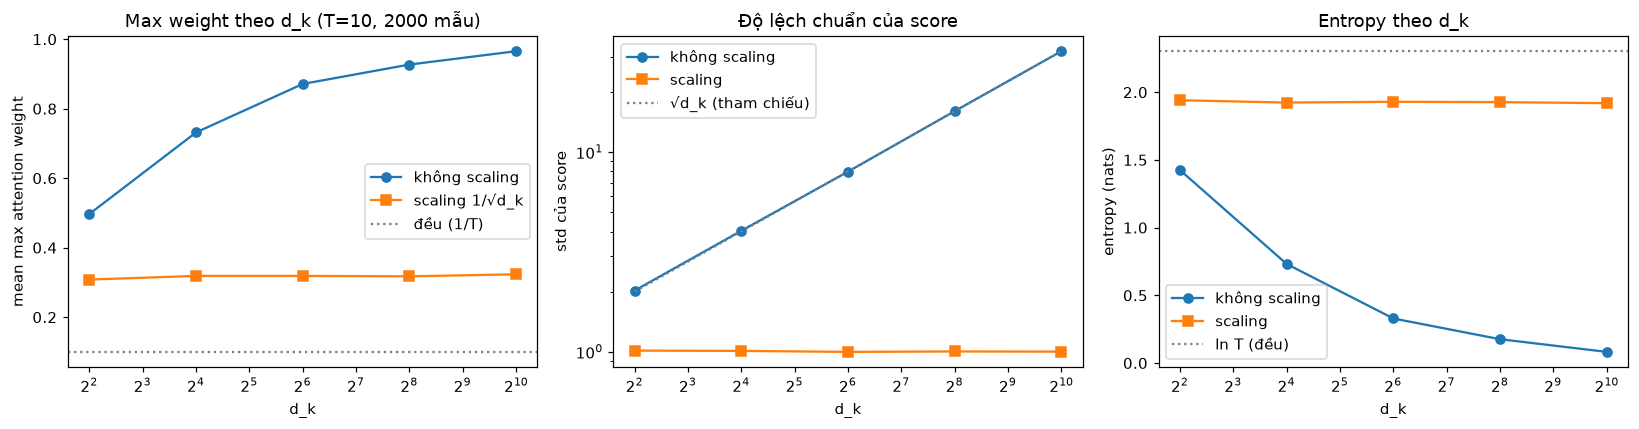

In [6]:
fig, ax = plt.subplots(1, 3, figsize=(15, 4))
ax[0].plot(sim['d_k'], sim['mean max weight (no scale)'], 'o-', label='không scaling')
ax[0].plot(sim['d_k'], sim['mean max weight (scaled)'], 's-', label='scaling 1/√d_k')
ax[0].axhline(1 / T_keys, ls=':', c='gray', label='đều (1/T)')
ax[0].set_xscale('log', base=2); ax[0].set_xlabel('d_k'); ax[0].set_ylabel('mean max attention weight'); ax[0].legend(); ax[0].set_title('Max weight theo d_k (T=10, 2000 mẫu)')
ax[1].plot(sim['d_k'], sim['std(qᵀk) không scaling'], 'o-', label='không scaling')
ax[1].plot(sim['d_k'], sim['std(qᵀk/√d_k)'], 's-', label='scaling')
ax[1].plot(sim['d_k'], np.sqrt(sim['d_k']), ':', c='gray', label='√d_k (tham chiếu)')
ax[1].set_xscale('log', base=2); ax[1].set_yscale('log'); ax[1].set_xlabel('d_k'); ax[1].set_ylabel('std của score'); ax[1].legend(); ax[1].set_title('Độ lệch chuẩn của score')
ax[2].plot(sim['d_k'], sim['mean entropy (no scale)'], 'o-', label='không scaling')
ax[2].plot(sim['d_k'], sim['mean entropy (scaled)'], 's-', label='scaling')
ax[2].axhline(np.log(T_keys), ls=':', c='gray', label='ln T (đều)')
ax[2].set_xscale('log', base=2); ax[2].set_xlabel('d_k'); ax[2].set_ylabel('entropy (nats)'); ax[2].legend(); ax[2].set_title('Entropy theo d_k')
plt.tight_layout(); plt.savefig(OUT / 'scaling_experiment.png', bbox_inches='tight'); plt.show()

In [7]:
print('Quan sát từ số liệu:')
print(f'- Ví dụ d_k=4: scores {qk.tolist()} -> {scaled.tolist()}. Max weight {w_raw.max():.4f} (không scaling) so với {w_scaled.max():.4f} (scaling); '
      f'entropy {entropy(w_raw):.4f} so với {entropy(w_scaled):.4f} nats. Scaling làm softmax bớt nhọn (max giảm, entropy tăng).')
first, last = sim.iloc[0], sim.iloc[-1]
print(f'- std(qᵀk) không scaling: {first["std(qᵀk) không scaling"]:.2f} (d_k={int(first.d_k)}) -> {last["std(qᵀk) không scaling"]:.2f} (d_k={int(last.d_k)}); '
      f'có scaling: {first["std(qᵀk/√d_k)"]:.2f} -> {last["std(qᵀk/√d_k)"]:.2f}.')
print(f'- Mean max weight không scaling: {first["mean max weight (no scale)"]:.3f} -> {last["mean max weight (no scale)"]:.3f}; '
      f'có scaling: {first["mean max weight (scaled)"]:.3f} -> {last["mean max weight (scaled)"]:.3f} (đều sẽ là {1/T_keys:.1f}, one-hot là 1.0).')
print(f'- Entropy không scaling: {first["mean entropy (no scale)"]:.3f} -> {last["mean entropy (no scale)"]:.3f}; có scaling: {first["mean entropy (scaled)"]:.3f} -> {last["mean entropy (scaled)"]:.3f} (ln T = {np.log(T_keys):.3f}).')

Quan sát từ số liệu:
- Ví dụ d_k=4: scores [4.0, 2.0, 0.0] -> [2.0, 1.0, 0.0]. Max weight 0.8668 (không scaling) so với 0.6652 (scaling); entropy 0.4411 so với 0.8324 nats. Scaling làm softmax bớt nhọn (max giảm, entropy tăng).
- std(qᵀk) không scaling: 2.02 (d_k=4) -> 32.02 (d_k=1024); có scaling: 1.01 -> 1.00.
- Mean max weight không scaling: 0.497 -> 0.966; có scaling: 0.308 -> 0.323 (đều sẽ là 0.1, one-hot là 1.0).
- Entropy không scaling: 1.425 -> 0.083; có scaling: 1.940 -> 1.919 (ln T = 2.303).


**Diễn giải của sinh viên**

Nếu các thành phần của q và k độc lập, trung bình 0, phương sai 1 thì qᵀk có phương sai d_k, tức độ lệch chuẩn √d_k. Mô phỏng khớp với điều này: std(qᵀk) tăng từ 2.02 (d_k = 4) lên 32.02 (d_k = 1024) khi không scaling, và giữ ≈ 1.0 khi chia √d_k. Score lớn làm softmax bão hòa: mean max weight không scaling tăng từ 0.497 lên 0.966 (entropy 1.425 xuống 0.083, gần one-hot), còn có scaling gần như không đổi (0.308 → 0.323). Ở ví dụ d_k = 4, scaling đưa max weight từ 0.8668 xuống 0.6652 và entropy từ 0.4411 lên 0.8324, tức làm softmax bớt nhọn. Softmax bão hòa có gradient rất nhỏ nên khó học; chia √d_k giữ độ lớn score ổn định bất kể d_k.

## B3. Temperature (mục 15)

**Mục tiêu:** quan sát `softmax(s / T)` với `s = [2, 1, 0]`, `T ∈ {0.5, 1.0, 2.0}`, rồi quét T rộng hơn (0.1 … 10).

In [8]:
s = np.array([2., 1., 0.])
expected = {0.5: (0.8668, 0.4411), 1.0: (0.6652, 0.8324), 2.0: (0.5065, 1.0202)}  # giá trị tham chiếu của đề bài
rows = []
for T in [0.5, 1.0, 2.0]:
    a = softmax(s, temperature=T)
    mw, h = a.max(), float(entropy(a))
    assert abs(mw - expected[T][0]) < 1e-3 and abs(h - expected[T][1]) < 1e-3, (T, mw, h)
    rows.append({'Temperature': T, 'weights': np.round(a, 4).tolist(), 'Max weight': mw, 'Entropy (nats)': h})
temp = pd.DataFrame(rows)
base = temp.loc[temp.Temperature == 1.0].iloc[0]
def comment(r):
    if r.Temperature == 1.0:
        return 'mốc so sánh'
    word = 'tập trung hơn' if r['Max weight'] > base['Max weight'] else 'phẳng hơn'
    return f"{word} T=1 (max {r['Max weight'] - base['Max weight']:+.4f}, entropy {r['Entropy (nats)'] - base['Entropy (nats)']:+.4f})"
temp['Nhận xét'] = temp.apply(comment, axis=1)
print('Tham chiếu của đề khớp (assert |sai lệch| < 1e-3). ln(3) =', round(float(np.log(3)), 4))
temp

Tham chiếu của đề khớp (assert |sai lệch| < 1e-3). ln(3) = 1.0986


,Temperature,weights,Max weight,Entropy (nats),Nhận xét
0,0.5,"[0.8668, 0.1173, 0.0159]",0.866813,0.441057,"tập trung hơn T=1 (max +0.2016, entropy -0.3913)"
1,1.0,"[0.6652, 0.2447, 0.09]",0.665241,0.832396,mốc so sánh
2,2.0,"[0.5065, 0.3072, 0.1863]",0.506480,1.020191,"phẳng hơn T=1 (max -0.1588, entropy +0.1878)"


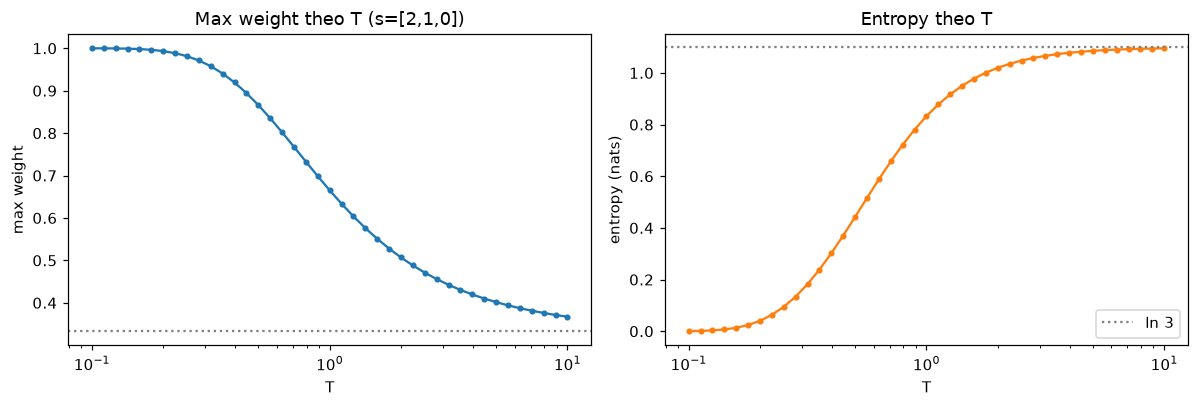

,T,max weight,entropy
0,0.1000,0.999955,0.000499
8,0.2512,0.981337,0.094494
16,0.6310,0.801916,0.588076
24,1.5849,0.550905,0.977962
32,3.9811,0.419644,1.077907
40,10.0000,0.367165,1.095287


In [9]:
grid = np.round(np.logspace(-1, 1, 41), 4)           # 0.1 ... 10
mx = np.array([softmax(s, temperature=t).max() for t in grid])
hh = np.array([entropy(softmax(s, temperature=t)) for t in grid])
fig, ax = plt.subplots(1, 2, figsize=(11, 3.8))
ax[0].plot(grid, mx, 'o-', ms=3); ax[0].axhline(1/3, ls=':', c='gray'); ax[0].set_xscale('log'); ax[0].set_xlabel('T'); ax[0].set_ylabel('max weight'); ax[0].set_title('Max weight theo T (s=[2,1,0])')
ax[1].plot(grid, hh, 'o-', ms=3, c='C1'); ax[1].axhline(np.log(3), ls=':', c='gray', label='ln 3'); ax[1].set_xscale('log'); ax[1].set_xlabel('T'); ax[1].set_ylabel('entropy (nats)'); ax[1].legend(); ax[1].set_title('Entropy theo T')
plt.tight_layout(); plt.savefig(OUT / 'temperature_experiment.png', bbox_inches='tight'); plt.show()
wide = pd.DataFrame({'T': grid, 'max weight': mx, 'entropy': hh}).iloc[::8]
wide

In [10]:
print('Quan sát từ số liệu:')
for _, r in temp.iterrows():
    print(f"- T={r.Temperature}: weights={r.weights}, max={r['Max weight']:.4f}, entropy={r['Entropy (nats)']:.4f} -> {r['Nhận xét']}")
print(f'- Quét T từ {grid[0]} đến {grid[-1]}: max weight giảm đơn điệu từ {mx[0]:.4f} xuống {mx[-1]:.4f} (đều = {1/3:.4f}); '
      f'entropy tăng đơn điệu từ {hh[0]:.4f} lên {hh[-1]:.4f} (tối đa ln3 = {np.log(3):.4f}). Đơn điệu: {bool(np.all(np.diff(mx) < 0) and np.all(np.diff(hh) > 0))}.')

Quan sát từ số liệu:
- T=0.5: weights=[0.8668, 0.1173, 0.0159], max=0.8668, entropy=0.4411 -> tập trung hơn T=1 (max +0.2016, entropy -0.3913)
- T=1.0: weights=[0.6652, 0.2447, 0.09], max=0.6652, entropy=0.8324 -> mốc so sánh
- T=2.0: weights=[0.5065, 0.3072, 0.1863], max=0.5065, entropy=1.0202 -> phẳng hơn T=1 (max -0.1588, entropy +0.1878)
- Quét T từ 0.1 đến 10.0: max weight giảm đơn điệu từ 1.0000 xuống 0.3672 (đều = 0.3333); entropy tăng đơn điệu từ 0.0005 lên 1.0953 (tối đa ln3 = 1.0986). Đơn điệu: True.


**Diễn giải của sinh viên**

Chia score cho T nhỏ phóng đại chênh lệch giữa các score nên phân phối nhọn hơn (T = 0.5: max 0.8668, entropy 0.4411); T lớn làm phẳng (T = 2: max 0.5065, entropy 1.0202). Khi quét T từ 0.1 đến 10, max weight giảm đơn điệu từ 1.0 xuống 0.367 (đều là 0.333) và entropy tăng dần tới giới hạn ln 3 = 1.0986. Scaling 1/√d_k thực chất là một temperature cố định T = √d_k: nó không đổi thứ tự các token mà chỉ điều chỉnh độ tập trung.

## B4. Experiment 1 — Attention distribution (mục 18)

**Mục tiêu:** quan sát model phân phối trọng số thế nào trên câu 10 token.

**Lưu ý quan trọng:** embedding và query ở đây là **giả lập**, do mình tự thiết kế (không học từ dữ liệu). Pattern vì vậy chỉ minh họa cơ chế `score → softmax → context`, không nói gì về hành vi của model thật.

Cách tạo embedding (6 chiều, seed 42): mỗi từ có một vector "đặc trưng" gán tay + nhiễu Gaussian N(0, 0.1²):
`[sent_pos, sent_neg, topic_noun, function, modifier, contrast]`, ví dụ `good = [1,0,0,0,0,0]`, `slow = [0,1,0,0,0,0]`, `movie = [0,0,1,0,0,0]`, `surprisingly = [0.2,0,0,0,1,0]`. Key = Value = embedding. Attention dùng đúng `scaled_dot_product_attention` (có chia √d_k).

In [11]:
SENT = 'The movie was surprisingly good despite a very slow beginning.'
tokens = SENT.rstrip('.').split()
assert len(tokens) == 10, tokens
FEATS = ['sent_pos', 'sent_neg', 'topic_noun', 'function', 'modifier', 'contrast']
LEX = {  # sent_pos, sent_neg, topic_noun, function, modifier, contrast
    'The': [0, 0, 0, 1, 0, 0],   'movie': [0, 0, 1, 0, 0, 0],   'was': [0, 0, 0, 1, 0, 0],
    'surprisingly': [0.2, 0, 0, 0, 1, 0], 'good': [1, 0, 0, 0, 0, 0], 'despite': [0, 0, 0, 0.5, 0, 1],
    'a': [0, 0, 0, 1, 0, 0],     'very': [0, 0, 0, 0, 1, 0],    'slow': [0, 1, 0, 0, 0, 0],
    'beginning': [0, 0, 0.7, 0, 0, 0],
}
rng = np.random.default_rng(SEED)
X1 = np.array([LEX[t] for t in tokens], dtype=float) + 0.1 * rng.standard_normal((len(tokens), len(FEATS)))
print('embedding X1 shape', X1.shape)
pd.DataFrame(np.round(X1, 2), index=tokens, columns=FEATS)

embedding X1 shape (10, 6)


,sent_pos,sent_neg,topic_noun,function,modifier,contrast
The,0.03,-0.10,0.08,1.09,-0.20,-0.13
movie,0.01,-0.03,1.00,-0.09,0.09,0.08
was,0.01,0.11,0.05,0.91,0.04,-0.10
surprisingly,0.29,-0.00,-0.02,-0.07,1.12,-0.02
good,0.96,-0.04,0.05,0.04,0.04,0.04
despite,0.21,-0.04,-0.05,0.42,0.06,1.11
a,-0.01,-0.08,-0.08,1.07,0.07,0.05
very,-0.07,0.02,0.01,0.02,1.09,0.02
slow,0.07,1.01,0.03,0.06,-0.15,-0.03
beginning,-0.05,-0.06,0.67,0.15,-0.09,0.10


In [12]:
q_sent  = np.array([[1.5, 1.5, 0, 0, 0.3, 0]])   # Query A: "tìm từ mang sentiment" (shape 1 x 6)
q_topic = np.array([[0, 0, 2.0, 0, 0, 0]])       # Query B: "tìm danh từ chủ đề" (dùng ở B5)

def attend_one(q, X):
    s, a, c = scaled_dot_product_attention(q, X, X)   # K = V = X
    return s[0], a[0], c[0]

s_A, a_A, c_A = attend_one(q_sent, X1)
tab1 = pd.DataFrame({'Token': tokens, 'Score': np.round(s_A, 4), 'Attention': np.round(a_A, 4)})
print('Query A (sentiment) q =', q_sent[0].tolist(), '| sum attention =', a_A.sum().round(6))
print('context c =', np.round(c_A, 4).tolist())
tab1

Query A (sentiment) q = [1.5, 1.5, 0.0, 0.0, 0.3, 0.0] | sum attention = 1.0
context c = [0.1953, 0.1379, 0.1432, 0.3012, 0.2092, 0.1037]


,Token,Score,Attention
0,The,-0.0689,0.0768
1,movie,-0.0008,0.0822
2,was,0.0776,0.0889
3,surprisingly,0.3107,0.1123
4,good,0.5696,0.1455
5,despite,0.1138,0.0922
6,a,-0.0493,0.0783
7,very,0.1066,0.0916
8,slow,0.6402,0.1561
9,beginning,-0.0785,0.0761


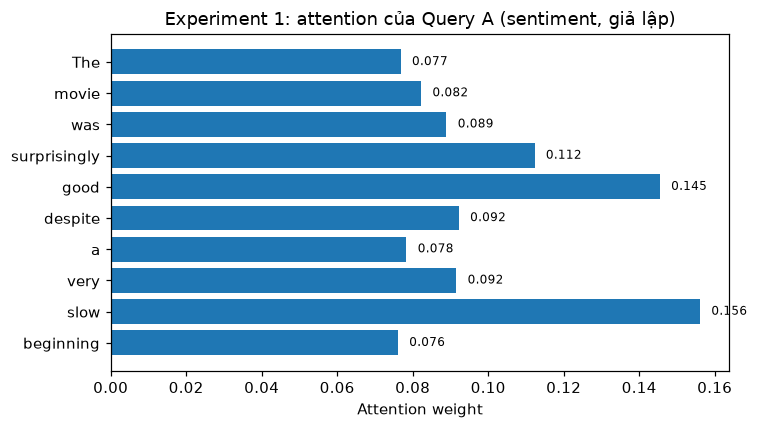

In [13]:
order = np.arange(len(tokens))
fig, ax = plt.subplots(figsize=(7, 4))
ax.barh(order, a_A, color='C0'); ax.set_yticks(order); ax.set_yticklabels(tokens); ax.invert_yaxis()
for i, v in enumerate(a_A): ax.text(v + 0.003, i, f'{v:.3f}', va='center', fontsize=8)
ax.set_xlabel('Attention weight'); ax.set_title('Experiment 1: attention của Query A (sentiment, giả lập)')
plt.tight_layout(); plt.savefig(OUT / 'exp1_attention_bar.png', bbox_inches='tight'); plt.show()

In [14]:
top = np.argsort(-a_A)
print('Quan sát từ số liệu:')
print(f'- Tổng attention = {a_A.sum():.4f}; token cao nhất: ' + ', '.join(f'{tokens[i]} ({a_A[i]:.3f})' for i in top[:3]) + f'; thấp nhất: {tokens[top[-1]]} ({a_A[top[-1]]:.3f}).')
print(f'- Max/min = {a_A.max()/a_A.min():.2f}x; entropy = {entropy(a_A):.4f} nats so với đều ln10 = {np.log(10):.4f}. Phân phối không one-hot: dù score chênh nhau, mọi token vẫn nhận > 0 (min = {a_A.min():.3f}).')
print('- Đây là kết quả của embedding/query giả lập: pattern phản ánh cách mình gán đặc trưng, không phản ánh model đã học.')

Quan sát từ số liệu:
- Tổng attention = 1.0000; token cao nhất: slow (0.156), good (0.145), surprisingly (0.112); thấp nhất: beginning (0.076).
- Max/min = 2.05x; entropy = 2.2678 nats so với đều ln10 = 2.3026. Phân phối không one-hot: dù score chênh nhau, mọi token vẫn nhận > 0 (min = 0.076).
- Đây là kết quả của embedding/query giả lập: pattern phản ánh cách mình gán đặc trưng, không phản ánh model đã học.


**Diễn giải của sinh viên**

Với query "sentiment" giả lập, `slow` (0.156) và `good` (0.145) có attention cao nhất, rồi `surprisingly` (0.112); `beginning` thấp nhất (0.076). Lý do là mình gán cho `good`/`slow` thành phần sentiment mà query nhắm tới, nên score của chúng cao hơn. Phân phối không one-hot (entropy 2.268 so với ln 10 = 2.303, max/min chỉ 2.05 lần): sau khi chia √d_k, chênh score nhỏ nên mọi token vẫn nhận trọng số đáng kể. Vì embedding và query là giả lập, kết quả chỉ minh họa cơ chế score → softmax → context, không phản ánh model đã học.

## B5. Experiment 2 — Query thay đổi (mục 19)

Cùng sequence, cùng K/V; chỉ đổi query: **A** = sentiment, **B** = topic (danh từ chủ đề).

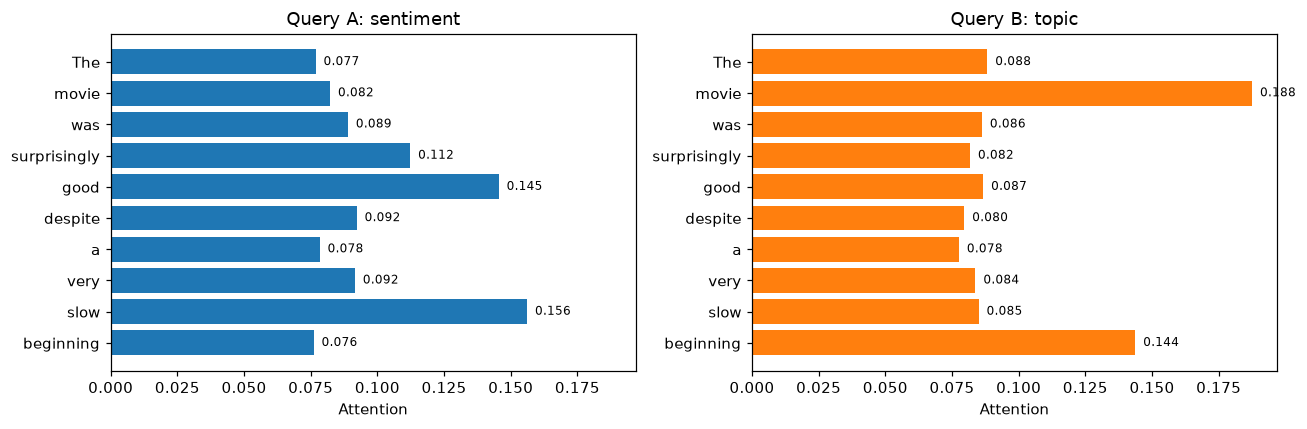

,Token,Attention A (sentiment),Attention B (topic)
0,The,0.0768,0.0882
1,movie,0.0822,0.1875
2,was,0.0889,0.0862
3,surprisingly,0.1123,0.0817
4,good,0.1455,0.0867
5,despite,0.0922,0.0796
6,a,0.0783,0.0776
7,very,0.0916,0.0838
8,slow,0.1561,0.0850
9,beginning,0.0761,0.1437


In [15]:
s_B, a_B, c_B = attend_one(q_topic, X1)
js, tv = jensen_shannon(a_A, a_B), total_variation(a_A, a_B)
uniform = np.full(10, 0.1)
fig, ax = plt.subplots(1, 2, figsize=(12, 4), sharex=True)
for a_, v, title, col in zip(ax, (a_A, a_B), ('Query A: sentiment', 'Query B: topic'), ('C0', 'C1')):
    a_.barh(order, v, color=col); a_.set_yticks(order); a_.set_yticklabels(tokens); a_.invert_yaxis(); a_.set_title(title); a_.set_xlabel('Attention')
    for i, x_ in enumerate(v): a_.text(x_ + 0.003, i, f'{x_:.3f}', va='center', fontsize=8)
plt.tight_layout(); plt.savefig(OUT / 'exp2_query_comparison.png', bbox_inches='tight'); plt.show()
cmp_tab = pd.DataFrame({'Token': tokens, 'Attention A (sentiment)': np.round(a_A, 4), 'Attention B (topic)': np.round(a_B, 4)})
cmp_tab

In [16]:
topA, topB = np.argsort(-a_A)[:3], np.argsort(-a_B)[:3]
print('Quan sát từ số liệu:')
print('- Top-3 Query A (sentiment):', ', '.join(f'{tokens[i]} ({a_A[i]:.3f})' for i in topA))
print('- Top-3 Query B (topic)    :', ', '.join(f'{tokens[i]} ({a_B[i]:.3f})' for i in topB))
print(f'- Khoảng cách giữa hai phân phối: Jensen–Shannon = {js:.4f} nats (tối đa ln2 = {np.log(2):.4f}); total variation = {tv:.4f} (tối đa 1). '
      f'Để so sánh: JS(A, đều) = {jensen_shannon(a_A, uniform):.4f}, JS(B, đều) = {jensen_shannon(a_B, uniform):.4f}.')
print(f'- Context vector khác nhau: c_A = {np.round(c_A,3).tolist()}, c_B = {np.round(c_B,3).tolist()}.')
print('- Cùng một câu, cùng K/V, chỉ đổi query thì top-token đổi -> attention phụ thuộc query (với embedding/query giả lập).')

Quan sát từ số liệu:
- Top-3 Query A (sentiment): slow (0.156), good (0.145), surprisingly (0.112)
- Top-3 Query B (topic)    : movie (0.188), beginning (0.144), The (0.088)
- Khoảng cách giữa hai phân phối: Jensen–Shannon = 0.0267 nats (tối đa ln2 = 0.6931); total variation = 0.1843 (tối đa 1). Để so sánh: JS(A, đều) = 0.0084, JS(B, đều) = 0.0118.
- Context vector khác nhau: c_A = [0.195, 0.138, 0.143, 0.301, 0.209, 0.104], c_B = [0.122, 0.06, 0.291, 0.302, 0.175, 0.103].
- Cùng một câu, cùng K/V, chỉ đổi query thì top-token đổi -> attention phụ thuộc query (với embedding/query giả lập).


**Diễn giải của sinh viên**

Cùng một câu, cùng K và V, chỉ đổi query: top-3 của query sentiment là `slow`, `good`, `surprisingly`, còn query topic là `movie` (0.188), `beginning` (0.144), `The` (0.088). Khoảng cách giữa hai phân phối: Jensen–Shannon = 0.0267 nats (tối đa ln 2 = 0.693), total variation = 0.1843. Giá trị này nhỏ vì cả hai phân phối đều khá phẳng; điều thay đổi rõ là thứ hạng token và context vector. Vậy attention không phải danh sách "từ quan trọng nhất" cố định của câu, mà phụ thuộc vào query.

## B6. Self-attention (mục 20–22)

Cho `["I", "like", "cats"]`. *Không tìm thấy ma trận do giảng viên cung cấp trong thư mục, nên dùng `X, W_Q, W_K, W_V` ghi trong yêu cầu thực hiện lab (đây là các giá trị để đối chiếu với phần tính tay).*

In [17]:
tok3 = ['I', 'like', 'cats']
X3 = np.array([[1, 0], [0, 1], [1, 1]], dtype=float)
W_Q = np.array([[1, 1], [0, 1]], dtype=float)
W_K = np.array([[1, 0], [1, 1]], dtype=float)
W_V = np.array([[1, 0], [0, 2]], dtype=float)
Q3, K3, V3, S3, A3, C3 = self_attention(X3, W_Q, W_K, W_V)
raw3 = Q3 @ K3.T
np.set_printoptions(precision=5, suppress=True)
for name, M in [('Q = X W_Q', Q3), ('K = X W_K', K3), ('V = X W_V', V3), ('Q Kᵀ', raw3), ('Q Kᵀ / √d_k  (d_k=2)', S3), ('A = softmax(.)', A3), ('C = A V', C3)]:
    print(name); print(M, '\n')
print('row sums of A:', A3.sum(1))
A_ref = np.array([[0.14003, 0.28400, 0.57598], [0.19778, 0.40111, 0.40111], [0.07432, 0.30570, 0.61999]])
C_ref = np.array([[0.7160, 1.7199], [0.5989, 1.6044], [0.6943, 1.8514]])
print('khớp giá trị tham chiếu:', np.allclose(A3, A_ref, atol=1e-4), np.allclose(C3, C_ref, atol=1e-4))

Q = X W_Q
[[1. 1.]
 [0. 1.]
 [1. 2.]] 

K = X W_K
[[1. 0.]
 [1. 1.]
 [2. 1.]] 

V = X W_V
[[1. 0.]
 [0. 2.]
 [1. 2.]] 

Q Kᵀ
[[1. 2. 3.]
 [0. 1. 1.]
 [1. 3. 4.]] 

Q Kᵀ / √d_k  (d_k=2)
[[0.70711 1.41421 2.12132]
 [0.      0.70711 0.70711]
 [0.70711 2.12132 2.82843]] 

A = softmax(.)
[[0.14003 0.284   0.57598]
 [0.19778 0.40111 0.40111]
 [0.07432 0.3057  0.61999]] 

C = A V
[[0.716   1.71994]
 [0.59889 1.60445]
 [0.6943  1.85136]] 

row sums of A: [1. 1. 1.]
khớp giá trị tham chiếu: True True


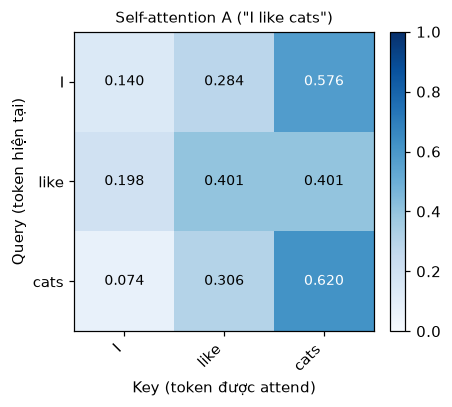

In [18]:
def heatmap(ax, M, row_labels, col_labels, title, fmt='{:.2f}', cmap='Blues', vmax=None, fs=9, xlabel='Key (token được attend)', ylabel='Query (token hiện tại)'):
    im = ax.imshow(M, cmap=cmap, vmin=0, vmax=vmax if vmax is not None else max(M.max(), 1e-9))
    ax.set_xticks(range(len(col_labels))); ax.set_xticklabels(col_labels, rotation=45, ha='right')
    ax.set_yticks(range(len(row_labels))); ax.set_yticklabels(row_labels)
    thr = 0.55 * im.get_clim()[1]
    if M.shape[0] * M.shape[1] <= 100:
        for i in range(M.shape[0]):
            for j in range(M.shape[1]):
                ax.text(j, i, fmt.format(M[i, j]), ha='center', va='center', fontsize=fs, color='white' if M[i, j] > thr else 'black')
    ax.set_title(title, fontsize=10); ax.set_xlabel(xlabel); ax.set_ylabel(ylabel)
    return im

fig, ax = plt.subplots(figsize=(4.2, 3.8))
im = heatmap(ax, A3, tok3, tok3, 'Self-attention A ("I like cats")', fmt='{:.3f}', vmax=1.0)
plt.colorbar(im, ax=ax, fraction=0.046); plt.tight_layout()
plt.savefig(OUT / 'attention_heatmap_b6.png', bbox_inches='tight'); plt.show()

In [19]:
print('Quan sát từ số liệu:')
for i, t in enumerate(tok3):
    j = int(np.argmax(A3[i]))
    print(f'- Hàng "{t}": attend nhiều nhất tới "{tok3[j]}" ({A3[i, j]:.3f}); phân phối = {np.round(A3[i], 3).tolist()}.')
print(f'- Tất cả hàng có tổng 1 ({np.round(A3.sum(1), 6).tolist()}). A không đối xứng: A[0,1]={A3[0,1]:.3f} khác A[1,0]={A3[1,0]:.3f} (Q và K dùng ma trận khác nhau).')
print(f'- Hàng "like" có hai key bằng nhau ({A3[1,1]:.5f}, {A3[1,2]:.5f}) vì K[like]·q và K[cats]·q cùng score = {S3[1,1]:.4f}.')

Quan sát từ số liệu:
- Hàng "I": attend nhiều nhất tới "cats" (0.576); phân phối = [0.14, 0.284, 0.576].
- Hàng "like": attend nhiều nhất tới "like" (0.401); phân phối = [0.198, 0.401, 0.401].
- Hàng "cats": attend nhiều nhất tới "cats" (0.620); phân phối = [0.074, 0.306, 0.62].
- Tất cả hàng có tổng 1 ([1.0, 1.0, 1.0]). A không đối xứng: A[0,1]=0.284 khác A[1,0]=0.198 (Q và K dùng ma trận khác nhau).
- Hàng "like" có hai key bằng nhau (0.40111, 0.40111) vì K[like]·q và K[cats]·q cùng score = 0.7071.


**Diễn giải của sinh viên**

Q = XW_Q là "token này đang tìm gì", K = XW_K là "token này có thể được tìm bằng gì", V = XW_V là "thông tin token này đóng góp nếu được chọn". QKᵀ[i, j] đo mức khớp giữa query của token i và key của token j; chia √d_k rồi softmax theo hàng cho phân phối attention của token i; C = AV là tổng có trọng số các V nên mỗi token mới chứa thông tin từ các token khác trong cùng sequence. Ví dụ: hàng "I" dành 0.576 cho "cats", hàng "cats" dành 0.620 cho chính nó. A không đối xứng (A[0,1] = 0.284 khác A[1,0] = 0.198) vì Q và K dùng ma trận khác nhau, và hàng "like" có hai key cùng score 0.7071 nên cùng weight 0.4011.

## B7. Experiment 3 — Attention visualization (mục 23)

Hai câu: `"The cat that I adopted yesterday is sleeping."` và `"The book that I bought yesterday was expensive."`

Hai cách, **khác nhau về bản chất**:

* **(a) Self-attention với embedding giả lập** (`d=16`): mỗi từ có vector Gaussian cố định theo hash của từ (cùng từ → cùng vector ở cả hai câu), `W_Q, W_K, W_V` ngẫu nhiên (seed 42), **chưa học gì**, không có position. Nó chỉ minh họa cơ chế tính; pattern gần như ngẫu nhiên theo độ tương đồng giữa các vector ngẫu nhiên, **không mang thông tin ngữ pháp**.
* **(b) Attention đọc từ `bert-base-uncased` đã pretrain** (chỉ để quan sát, không phải core implementation, không train thêm). Pattern ở đây đến từ model đã học, nhưng vẫn chỉ là *phân phối attention của một head/layer*, **không phải** giải thích ngôn ngữ học. Layer/head không được chọn theo "đẹp": cố định trước là trung bình các head của layer 3, 6, 9, 12.

> Attention pattern ≠ giải thích ngôn ngữ học. Heatmap là bằng chứng về phân phối attention, không tự động là bằng chứng model "hiểu ngữ pháp" hay đang reasoning.

In [20]:
sents = ['The cat that I adopted yesterday is sleeping.', 'The book that I bought yesterday was expensive.']
words = [s.rstrip('.').split() for s in sents]
targets = [['cat', 'adopted', 'sleeping'], ['book', 'bought', 'expensive']]

def word_vec(w: str, d: int = 16) -> np.ndarray:
    return np.random.default_rng(zlib.crc32(w.lower().encode())).standard_normal(d)   # cùng từ -> cùng vector

d_model7 = 16
rng7 = np.random.default_rng(SEED)
Wq7, Wk7, Wv7 = (rng7.standard_normal((d_model7, d_model7)) / np.sqrt(d_model7) for _ in range(3))
synth_A = []
for w in words:
    X = np.stack([word_vec(t) for t in w])                       # (8, 16)
    _, _, _, _, A, _ = self_attention(X, Wq7, Wk7, Wv7)          # A: (8, 8)
    synth_A.append(A)

def top3(A, toks, word, k=3):
    i = toks.index(word)
    idx = np.argsort(-A[i])[:k]
    return ', '.join(f'{toks[j]}{"(self)" if j == i else ""} {A[i, j]:.3f}' for j in idx)

rows = []
for si, (w, tg) in enumerate(zip(words, targets)):
    for t in tg:
        rows.append({'sentence': si + 1, 'token': t, 'top-3 attended (synthetic)': top3(synth_A[si], w, t)})
pd.DataFrame(rows)

,sentence,token,top-3 attended (synthetic)
0,1,cat,"adopted 0.402, is 0.228, I 0.129"
1,1,adopted,"The 0.438, cat 0.159, I 0.098"
2,1,sleeping,"that 0.203, sleeping(self) 0.183, yesterday 0.167"
3,2,book,"The 0.430, yesterday 0.149, I 0.141"
4,2,bought,"The 0.668, yesterday 0.172, I 0.076"
5,2,expensive,"The 0.217, that 0.156, yesterday 0.154"


In [21]:
import torch
from transformers import AutoTokenizer, AutoModel
BERT_LAYERS = [3, 6, 9, 12]          # 1-indexed, trung bình trên 12 head
bert_ok, bert_err = True, ''
try:
    tokz = AutoTokenizer.from_pretrained('bert-base-uncased')
    bert = AutoModel.from_pretrained('bert-base-uncased', attn_implementation='eager').eval()
    bert_A, bert_toks = [], []
    for s_ in sents:
        enc = tokz(s_, return_tensors='pt')
        with torch.no_grad():
            out = bert(**enc, output_attentions=True)
        bert_toks.append(tokz.convert_ids_to_tokens(enc['input_ids'][0]))
        bert_A.append({L: out.attentions[L - 1][0].mean(0).numpy() for L in BERT_LAYERS})   # (T, T) trung bình head
    print('BERT tokens:', bert_toks)
except Exception as e:                                    # không có mạng / không tải được model
    bert_ok, bert_err = False, f'{type(e).__name__}: {e}'
    print('Không tải được BERT, bỏ qua phần (b):', bert_err)

C:\Users\Admin\AppData\Roaming\Python\Python314\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm



Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]


Loading weights: 100%|██████████| 199/199 [00:00<00:00, 5114.88it/s]


[transformers] BertModel LOAD REPORT from: bert-base-uncased
Key                                        | Status     |  | 
-------------------------------------------+------------+--+-
cls.predictions.bias                       | UNEXPECTED |  | 
cls.predictions.transform.dense.weight     | UNEXPECTED |  | 
cls.seq_relationship.bias                  | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED |  | 
cls.predictions.transform.dense.bias       | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED |  | 
cls.seq_relationship.weight                | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


BERT tokens: [['[CLS]', 'the', 'cat', 'that', 'i', 'adopted', 'yesterday', 'is', 'sleeping', '.', '[SEP]'], ['[CLS]', 'the', 'book', 'that', 'i', 'bought', 'yesterday', 'was', 'expensive', '.', '[SEP]']]


In [22]:
if bert_ok:
    rows = []
    for si in range(2):
        toks = bert_toks[si]
        for t in targets[si]:
            for L in BERT_LAYERS:
                rows.append({'sentence': si + 1, 'token': t, 'layer': L, 'top-3 attended (BERT, head-avg)': top3(bert_A[si][L], toks, t)})
    bert_tab = pd.DataFrame(rows)
    # tỷ lệ attention mass của các token mục tiêu rơi vào [CLS]/[SEP]/dấu chấm
    special = {'[CLS]', '[SEP]', '.'}
    mass = {}
    for L in BERT_LAYERS:
        v = []
        for si in range(2):
            toks = bert_toks[si]
            for t in targets[si]:
                row = bert_A[si][L][toks.index(t)]
                v.append(sum(row[j] for j, tk in enumerate(toks) if tk in special))
        mass[L] = float(np.mean(v))
    print('Tỷ lệ attention mass dồn vào [CLS]/[SEP]/"." (trung bình 6 token mục tiêu) theo layer:', {k: round(v, 3) for k, v in mass.items()})
    bert_tab

Tỷ lệ attention mass dồn vào [CLS]/[SEP]/"." (trung bình 6 token mục tiêu) theo layer: {3: 0.503, 6: 0.773, 9: 0.712, 12: 0.792}


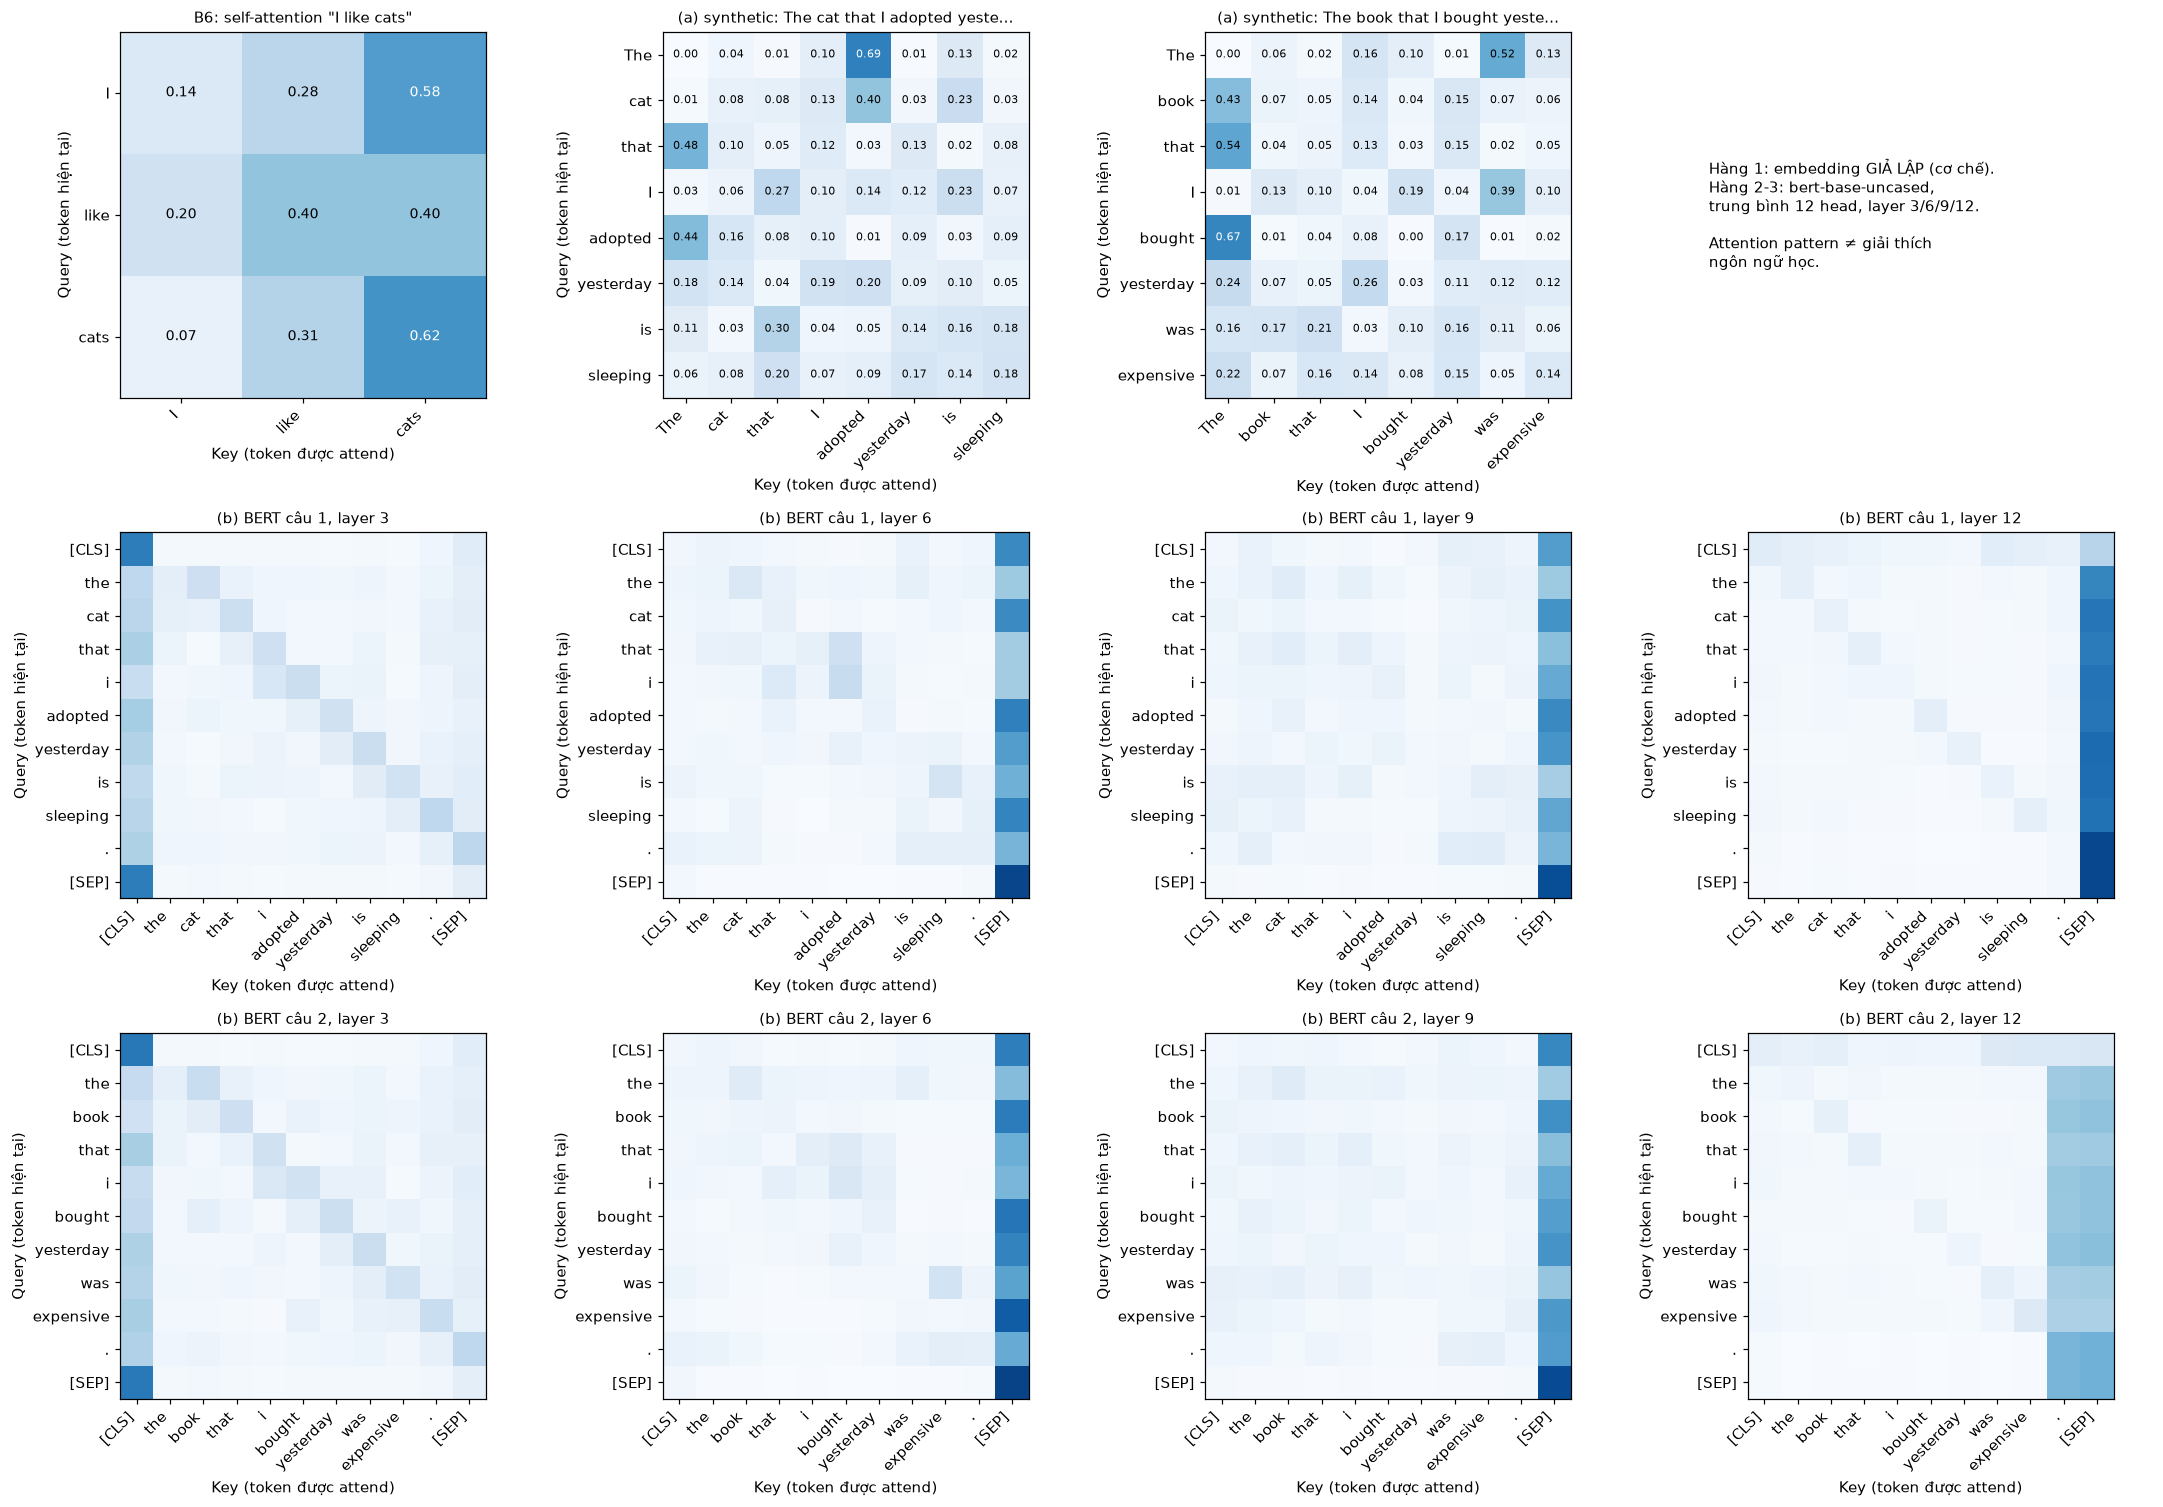

In [23]:
# Hình tổng hợp -> attention_heatmap.png (hàng 1: B6 + synthetic; hàng 2-3: BERT)
ncols = 4
fig, axes = plt.subplots(3 if bert_ok else 1, ncols, figsize=(5.0 * ncols, 4.6 * (3 if bert_ok else 1)))
axes = np.atleast_2d(axes)
heatmap(axes[0, 0], A3, tok3, tok3, 'B6: self-attention "I like cats"', fmt='{:.2f}', vmax=1.0)
heatmap(axes[0, 1], synth_A[0], words[0], words[0], '(a) synthetic: ' + sents[0][:28] + '...', fmt='{:.2f}', vmax=1.0, fs=7)
heatmap(axes[0, 2], synth_A[1], words[1], words[1], '(a) synthetic: ' + sents[1][:28] + '...', fmt='{:.2f}', vmax=1.0, fs=7)
axes[0, 3].axis('off')
axes[0, 3].text(0, 0.5, 'Hàng 1: embedding GIẢ LẬP (cơ chế).\nHàng 2-3: bert-base-uncased,\ntrung bình 12 head, layer 3/6/9/12.\n\nAttention pattern ≠ giải thích\nngôn ngữ học.', fontsize=10, va='center')
if bert_ok:
    for si in range(2):
        for ci, L in enumerate(BERT_LAYERS):
            ax = axes[1 + si, ci]
            heatmap(ax, bert_A[si][L], bert_toks[si], bert_toks[si], f'(b) BERT câu {si+1}, layer {L}', fmt='{:.2f}', vmax=1.0, fs=6)
plt.tight_layout(); plt.savefig(OUT / 'attention_heatmap.png', bbox_inches='tight'); plt.show()
# file phụ
fig, ax = plt.subplots(1, 2, figsize=(11, 4.6))
for k in range(2): heatmap(ax[k], synth_A[k], words[k], words[k], f'(a) synthetic, câu {k+1}', fmt='{:.2f}', vmax=1.0, fs=7)
plt.tight_layout(); plt.savefig(OUT / 'attention_heatmap_synthetic.png', bbox_inches='tight'); plt.close()
if bert_ok:
    fig, ax = plt.subplots(2, 4, figsize=(20, 10))
    for si in range(2):
        for ci, L in enumerate(BERT_LAYERS): heatmap(ax[si, ci], bert_A[si][L], bert_toks[si], bert_toks[si], f'BERT câu {si+1}, layer {L}', fmt='{:.2f}', vmax=1.0, fs=6)
    plt.tight_layout(); plt.savefig(OUT / 'attention_heatmap_bert.png', bbox_inches='tight'); plt.close()

In [24]:
print('Quan sát từ số liệu:')
print('- (a) Embedding giả lập, top-3 attended:')
for si in range(2):
    for t in targets[si]:
        print(f'    câu {si+1} "{t}": {top3(synth_A[si], words[si], t)}')
print('  Cùng một từ ở hai câu (vd. "that", "I", "yesterday") có vector giống hệt nhau, nên khác biệt giữa hai heatmap chỉ đến từ các từ khác nhau (cat/book, adopted/bought, is sleeping/was expensive).')
if bert_ok:
    print('- (b) BERT head-avg: tỷ lệ attention mass của 6 token mục tiêu dồn vào [CLS]/[SEP]/"." theo layer =', {k: round(v, 3) for k, v in mass.items()})
    for si in range(2):
        for t in targets[si]:
            print(f'    câu {si+1} "{t}", layer 12: {top3(bert_A[si][12], bert_toks[si], t)}')
    print('  Chú ý: nếu phần lớn mass dồn vào token đặc biệt thì top-3 của token mục tiêu chủ yếu là [CLS]/[SEP]/dấu chấm, không nên đọc đó như quan hệ cú pháp.')
else:
    print('- (b) Không chạy được BERT:', bert_err)
print('- Không có bằng chứng nào ở đây cho thấy model "hiểu ngữ pháp": ta chỉ quan sát phân phối attention của các head trung bình.')

Quan sát từ số liệu:
- (a) Embedding giả lập, top-3 attended:
    câu 1 "cat": adopted 0.402, is 0.228, I 0.129
    câu 1 "adopted": The 0.438, cat 0.159, I 0.098
    câu 1 "sleeping": that 0.203, sleeping(self) 0.183, yesterday 0.167
    câu 2 "book": The 0.430, yesterday 0.149, I 0.141
    câu 2 "bought": The 0.668, yesterday 0.172, I 0.076
    câu 2 "expensive": The 0.217, that 0.156, yesterday 0.154
  Cùng một từ ở hai câu (vd. "that", "I", "yesterday") có vector giống hệt nhau, nên khác biệt giữa hai heatmap chỉ đến từ các từ khác nhau (cat/book, adopted/bought, is sleeping/was expensive).
- (b) BERT head-avg: tỷ lệ attention mass của 6 token mục tiêu dồn vào [CLS]/[SEP]/"." theo layer = {3: 0.503, 6: 0.773, 9: 0.712, 12: 0.792}
    câu 1 "cat", layer 12: [SEP] 0.729, cat(self) 0.074, . 0.044
    câu 1 "adopted", layer 12: [SEP] 0.728, adopted(self) 0.097, . 0.035
    câu 1 "sleeping", layer 12: [SEP] 0.748, sleeping(self) 0.093, . 0.039
    câu 2 "book", layer 12: [SEP] 0.406, . 

**Diễn giải của sinh viên**

Với embedding giả lập, pattern chỉ phản ánh độ tương đồng giữa các vector ngẫu nhiên sau khi chiếu bằng W ngẫu nhiên: ví dụ "bought" dồn 0.668 vào "The", không có ý nghĩa ngữ pháp. Với BERT (trung bình 12 head), attention mass của 6 token mục tiêu rơi vào `[CLS]`/`[SEP]`/`.` là 0.503 ở layer 3 và 0.71–0.79 ở layer 6, 9, 12; ví dụ ở layer 12, "cat" dành 0.729 cho `[SEP]`. Vì vậy top-3 của `cat`, `adopted`, `sleeping` chủ yếu là token đặc biệt hoặc chính nó, và không cho biết `cat` là chủ ngữ của `sleeping`. Heatmap chỉ là phân phối attention của một layer; giải thích ngôn ngữ học cần bằng chứng khác (can thiệp, probing). Nên mình không kết luận model "hiểu ngữ pháp".

## B8. Experiment 4 — RNN context vs Attention context (mục 24)

**Dataset / tiền xử lý / split: đúng của LAB 05** (đọc trực tiếp `../Lab05/data/{train,test}.csv` và dùng lại `sequence_models.py` của LAB 05): IMDb 50k review do giảng viên cung cấp (file CSV có sẵn), tokenizer chữ thường giữ negation/contraction, vocab 30 000 xây từ train, cắt `max_length = 100` giữ 100 token đầu, split stratified 80/20 seed 42 + loại trùng lặp giữa các split.

Hai model, cùng embedding dim (64), cùng Adam (lr 1e-3), batch 128, **3 epoch**, cùng seed (42, 43, 44):

1. `Embedding → LSTM(64) → final hidden state (bước cuối hợp lệ) → Linear`
2. `Embedding + learnable position embedding (100 vị trí) → self-attention tự viết (W_Q, W_K, W_V: Linear 64→64, 1 head, mask padding) → mean pooling (có mask) trên context → Linear`

Self-attention thuần túy không biết thứ tự nên model 2 cần position embedding; ở đây dùng kiểu đơn giản nhất (learnable), chưa phải positional encoding sin/cos của Transformer.

In [25]:
import attention_models as am
import torch
from sklearn.metrics import classification_report

dev = am.get_device()
gpu = torch.cuda.get_device_name(0) if dev.type == 'cuda' else 'CPU'
data = am.load_lab05_data()
vocab = data.vocab
ds_train, ds_val, ds_test = (am.make_dataset(f, vocab) for f in (data.train, data.val, data.test))
N_TRAIN, N_VAL, N_TEST = len(data.train), len(data.val), len(data.test)
DATASET = 'IMDb-50k (LAB05 CSV split, seeded 80/20, dedup)'
print('source :', data.source)
print(f'sizes  : train={N_TRAIN} val={N_VAL} test={N_TEST} | vocab={len(vocab)} | max_len={am.MAX_LEN} | device={gpu}')
print('test class balance:', data.test.label.value_counts().to_dict())

source : local CSV partitions: D:\Study\Semester 7\NLP\Lab05\data
sizes  : train=31879 val=7904 test=10000 | vocab=30000 | max_len=100 | device=NVIDIA GeForce RTX 3050 6GB Laptop GPU
test class balance: {1: 5000, 0: 5000}


In [26]:
SEEDS = [42, 43, 44]
MODELS = [('LSTM', am.LSTMClassifier), ('Self-attention', am.AttentionClassifier)]
runs, models42, probs42, y_test = [], {}, {}, None
val_loader, test_loader = am.make_loader(ds_val, False), am.make_loader(ds_test, False)
for seed in SEEDS:
    for name, cls in MODELS:
        am.set_seed(seed)
        model = cls(len(vocab))
        print(f'[{name}] seed={seed} params={am.count_params(model):,}')
        res = am.train_model(model, am.make_loader(ds_train, True, seed), val_loader, dev, epochs=am.EPOCHS)
        p, y, _ = am.predict_loader(model, test_loader, dev)
        m = am.metrics(y, p)
        runs.append({'model': name, 'seed': seed, 'epochs': am.EPOCHS, 'dataset': DATASET,
                     'accuracy': m['accuracy'], 'f1_macro': m['f1_macro'], 'train_time_s': res['train_time'],
                     'parameters': am.count_params(model), 'n_train': N_TRAIN, 'n_val': N_VAL, 'n_test': N_TEST, 'device': gpu})
        print(f"   test acc={m['accuracy']:.4f} f1={m['f1_macro']:.4f} train_time={res['train_time']:.1f}s")
        if seed == 42:
            models42[name], probs42[name], y_test = model, p, y
runs_df = pd.DataFrame(runs)
runs_df

[LSTM] seed=42 params=1,953,345


  epoch 1: train_loss=0.6797 val_loss=0.6474 val_acc=0.6311


  epoch 2: train_loss=0.6360 val_loss=0.5941 val_acc=0.6865


  epoch 3: train_loss=0.5299 val_loss=0.5095 val_acc=0.7559


   test acc=0.7583 f1=0.7578 train_time=16.5s
[Self-attention] seed=42 params=1,938,753


...

  epoch 1: train_loss=0.6067 val_loss=0.5077 val_acc=0.7495


  epoch 2: train_loss=0.4462 val_loss=0.4291 val_acc=0.7982


  epoch 3: train_loss=0.3640 val_loss=0.4034 val_acc=0.8168


   test acc=0.8140 f1=0.8140 train_time=7.2s


,model,seed,epochs,dataset,accuracy,f1_macro,train_time_s,parameters,n_train,n_val,n_test,device
0,LSTM,42,3,"IMDb-50k (LAB05 CSV split, seeded 80/20, dedup)",0.7583,0.757781,16.456393,1953345,31879,7904,10000,NVIDIA GeForce RTX 3050 6GB Laptop GPU
1,Self-attention,42,3,"IMDb-50k (LAB05 CSV split, seeded 80/20, dedup)",0.8066,0.806366,7.864533,1938753,31879,7904,10000,NVIDIA GeForce RTX 3050 6GB Laptop GPU
2,LSTM,43,3,"IMDb-50k (LAB05 CSV split, seeded 80/20, dedup)",0.7963,0.796028,14.676682,1953345,31879,7904,10000,NVIDIA GeForce RTX 3050 6GB Laptop GPU
3,Self-attention,43,3,"IMDb-50k (LAB05 CSV split, seeded 80/20, dedup)",0.8099,0.809679,7.491986,1938753,31879,7904,10000,NVIDIA GeForce RTX 3050 6GB Laptop GPU
4,LSTM,44,3,"IMDb-50k (LAB05 CSV split, seeded 80/20, dedup)",0.7384,0.737938,12.373885,1953345,31879,7904,10000,NVIDIA GeForce RTX 3050 6GB Laptop GPU
5,Self-attention,44,3,"IMDb-50k (LAB05 CSV split, seeded 80/20, dedup)",0.8140,0.814000,7.170339,1938753,31879,7904,10000,NVIDIA GeForce RTX 3050 6GB Laptop GPU


In [27]:
agg = runs_df.groupby('model').agg(
    accuracy_mean=('accuracy', 'mean'), accuracy_std=('accuracy', 'std'),
    f1_mean=('f1_macro', 'mean'), f1_std=('f1_macro', 'std'),
    time_mean=('train_time_s', 'mean'), time_std=('train_time_s', 'std'), parameters=('parameters', 'first')).reindex(['LSTM', 'Self-attention'])
summary = pd.DataFrame({
    'Model': agg.index,
    'Accuracy': [f'{r.accuracy_mean:.4f} ± {r.accuracy_std:.4f}' for r in agg.itertuples()],
    'F1 (macro)': [f'{r.f1_mean:.4f} ± {r.f1_std:.4f}' for r in agg.itertuples()],
    'Training time (s)': [f'{r.time_mean:.1f} ± {r.time_std:.1f}' for r in agg.itertuples()],
    '#Parameters': [f'{int(r.parameters):,}' for r in agg.itertuples()]})
print(f'Test set (n={N_TEST}), mean ± std (sample std) over seeds {SEEDS}, {am.EPOCHS} epochs, device={gpu}')
summary

Test set (n=10000), mean ± std (sample std) over seeds [42, 43, 44], 3 epochs, device=NVIDIA GeForce RTX 3050 6GB Laptop GPU


,Model,Accuracy,F1 (macro),Training time (s),#Parameters
0,LSTM,0.7643 ± 0.0294,0.7639 ± 0.0295,14.5 ± 2.0,"1,953,345"
1,Self-attention,0.8102 ± 0.0037,0.8100 ± 0.0038,7.5 ± 0.3,"1,938,753"


In [28]:
# results.csv: từng seed + dòng mean / std
extra = []
for stat in ('mean', 'std'):
    for name in ('LSTM', 'Self-attention'):
        sub = runs_df[runs_df.model == name]
        row = {'model': name, 'seed': stat, 'epochs': am.EPOCHS, 'dataset': DATASET, 'parameters': int(sub.parameters.iloc[0]),
               'n_train': N_TRAIN, 'n_val': N_VAL, 'n_test': N_TEST, 'device': gpu}
        for c in ('accuracy', 'f1_macro', 'train_time_s'):
            row[c] = getattr(sub[c], stat)()
        extra.append(row)
results = pd.concat([runs_df, pd.DataFrame(extra)], ignore_index=True)
cols = ['model', 'seed', 'epochs', 'dataset', 'accuracy', 'f1_macro', 'train_time_s', 'parameters', 'n_train', 'n_val', 'n_test', 'device']
results[cols].to_csv(OUT / 'results.csv', index=False, float_format='%.6f')
print(pd.read_csv(OUT / 'results.csv').drop(columns=['dataset', 'device', 'n_train', 'n_val', 'n_test']).to_string(index=False))

         model seed  epochs  accuracy  f1_macro  train_time_s  parameters
          LSTM   42       3  0.758300  0.757781     16.456393     1953345
Self-attention   42       3  0.806600  0.806366      7.864533     1938753
          LSTM   43       3  0.796300  0.796028     14.676682     1953345
Self-attention   43       3  0.809900  0.809679      7.491986     1938753
          LSTM   44       3  0.738400  0.737938     12.373885     1953345
Self-attention   44       3  0.814000  0.814000      7.170339     1938753
          LSTM mean       3  0.764333  0.763916     14.502320     1953345
Self-attention mean       3  0.810167  0.810015      7.508953     1938753
          LSTM  std       3  0.029418  0.029527      2.046832     1953345
Self-attention  std       3  0.003707  0.003828      0.347408     1938753


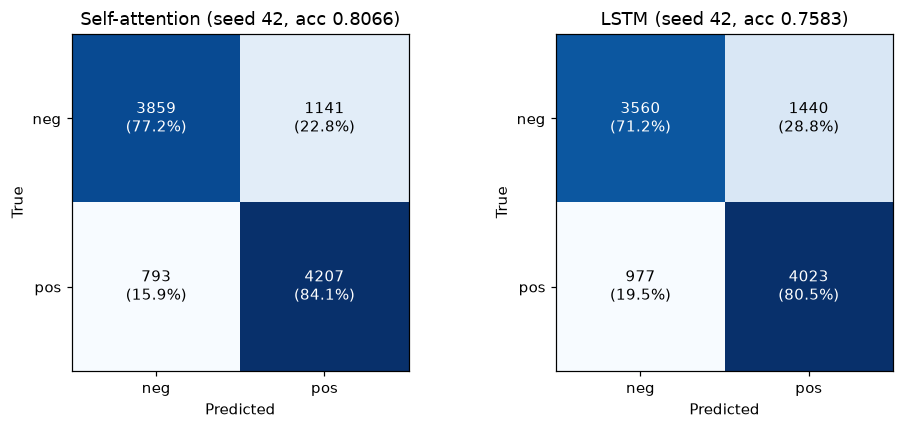

Self-attention 
               precision    recall  f1-score   support

         neg     0.8295    0.7718    0.7996      5000
         pos     0.7866    0.8414    0.8131      5000

    accuracy                         0.8066     10000
   macro avg     0.8081    0.8066    0.8064     10000
weighted avg     0.8081    0.8066    0.8064     10000

LSTM 
               precision    recall  f1-score   support

         neg     0.7847    0.7120    0.7466      5000
         pos     0.7364    0.8046    0.7690      5000

    accuracy                         0.7583     10000
   macro avg     0.7605    0.7583    0.7578     10000
weighted avg     0.7605    0.7583    0.7578     10000



In [29]:
fig, ax = plt.subplots(1, 2, figsize=(9, 4))
for a_, name in zip(ax, ['Self-attention', 'LSTM']):
    cm = am.confusion(y_test, probs42[name])
    a_.imshow(cm, cmap='Blues')
    for i in range(2):
        for j in range(2): a_.text(j, i, f'{cm[i, j]}\n({cm[i, j] / cm[i].sum():.1%})', ha='center', va='center', color='white' if cm[i, j] > cm.max() / 2 else 'black')
    a_.set_xticks([0, 1]); a_.set_xticklabels(['neg', 'pos']); a_.set_yticks([0, 1]); a_.set_yticklabels(['neg', 'pos'])
    a_.set_xlabel('Predicted'); a_.set_ylabel('True'); a_.set_title(f'{name} (seed 42, acc {am.metrics(y_test, probs42[name])["accuracy"]:.4f})')
plt.tight_layout(); plt.savefig(OUT / 'confusion_matrix.png', bbox_inches='tight'); plt.show()
for name in ['Self-attention', 'LSTM']:
    print(name, '\n', classification_report(y_test, (probs42[name] >= 0.5).astype(int), target_names=['neg', 'pos'], digits=4))

In [30]:
a, l = agg.loc['Self-attention'], agg.loc['LSTM']
print('Quan sát từ số liệu:')
print(f'- Accuracy: Self-attention {a.accuracy_mean:.4f} ± {a.accuracy_std:.4f} so với LSTM {l.accuracy_mean:.4f} ± {l.accuracy_std:.4f} (chênh {a.accuracy_mean - l.accuracy_mean:+.4f}); '
      f'F1 macro {a.f1_mean:.4f} so với {l.f1_mean:.4f}.')
better = 'Self-attention' if a.accuracy_mean > l.accuracy_mean else 'LSTM'
per_seed_win = int((runs_df[runs_df.model == 'Self-attention'].accuracy.values > runs_df[runs_df.model == 'LSTM'].accuracy.values).sum())
print(f'- Model có accuracy trung bình cao hơn: {better}; Self-attention thắng {per_seed_win}/{len(SEEDS)} seed. Chỉ 3 seed, 3 epoch, một cấu hình siêu tham số -> không đủ để kết luận tổng quát.')
print(f'- Tham số: LSTM {int(l.parameters):,} so với Self-attention {int(a.parameters):,} ({a.parameters / l.parameters:.3f}x); phần lớn (30000x64 = {30000*64:,}) là embedding ở cả hai.')
print(f'- Thời gian train (GPU {gpu}): LSTM {l.time_mean:.1f}s, Self-attention {a.time_mean:.1f}s (tỷ lệ {l.time_mean / a.time_mean:.2f}x). Thời gian đo trên một GPU, chỉ vòng huấn luyện, không tính validation.')
print('- Khác biệt representation: LSTM nén chuỗi (tối đa 100 token) vào 1 vector h_T qua 100 bước tuần tự; Self-attention cho mỗi vị trí trộn trực tiếp mọi vị trí (ma trận 100x100 mỗi câu) rồi mean-pool (mọi vị trí đóng góp như nhau sau khi trộn).')
print('- Ở cấu hình này mean-pooling của context cho kết quả gần với bag-of-words có ngữ cảnh; chưa có thí nghiệm ablation (bỏ position, đổi pooling) nên không kết luận được phần nào gây ra chênh lệch.')

Quan sát từ số liệu:
- Accuracy: Self-attention 0.8102 ± 0.0037 so với LSTM 0.7643 ± 0.0294 (chênh +0.0458); F1 macro 0.8100 so với 0.7639.
- Model có accuracy trung bình cao hơn: Self-attention; Self-attention thắng 3/3 seed. Chỉ 3 seed, 3 epoch, một cấu hình siêu tham số -> không đủ để kết luận tổng quát.
- Tham số: LSTM 1,953,345 so với Self-attention 1,938,753 (0.993x); phần lớn (30000x64 = 1,920,000) là embedding ở cả hai.
- Thời gian train (GPU NVIDIA GeForce RTX 3050 6GB Laptop GPU): LSTM 14.5s, Self-attention 7.5s (tỷ lệ 1.93x). Thời gian đo trên một GPU, chỉ vòng huấn luyện, không tính validation.
- Khác biệt representation: LSTM nén chuỗi (tối đa 100 token) vào 1 vector h_T qua 100 bước tuần tự; Self-attention cho mỗi vị trí trộn trực tiếp mọi vị trí (ma trận 100x100 mỗi câu) rồi mean-pool (mọi vị trí đóng góp như nhau sau khi trộn).
- Ở cấu hình này mean-pooling của context cho kết quả gần với bag-of-words có ngữ cảnh; chưa có thí nghiệm ablation (bỏ position, đổi pooling) n

**Diễn giải của sinh viên**

LSTM nén cả chuỗi (tối đa 100 token) vào vector h_T qua các bước tuần tự, nên thông tin ở đầu phải đi qua nhiều bước. Self-attention cho mỗi vị trí truy cập trực tiếp mọi vị trí rồi mean-pool; nó cần position embedding vì tự thân không có thứ tự. Số liệu: accuracy 0.8102 ± 0.0037 so với 0.7643 ± 0.0294 và F1 macro 0.8100 so với 0.7639; self-attention thắng ở cả 3 seed, train nhanh gần gấp đôi, số tham số gần bằng nhau (1.94M so với 1.95M, trong đó 1.92M là embedding), và độ lệch chuẩn nhỏ hơn nhiều. Tuy nhiên mới có 3 seed, 3 epoch, một cấu hình siêu tham số, nên chưa kết luận attention tốt hơn LSTM nói chung: LSTM có thể học chậm hơn trong 3 epoch, và mean pooling gần giống bag-of-words nên chưa chứng minh model dùng ngữ cảnh. Cần ablation (bỏ position, đổi pooling, train lâu hơn) để biết nguyên nhân.

## B9. Experiment 5 — Sequence length và chi phí (mục 25, 29)

(1) Kích thước ma trận attention `T × T` (float32, 1 MB = 10⁶ byte). (2) Đo thời gian thật của `scaled_dot_product_attention` (NumPy, float64, `d_k = d_v = 64`, Q = K = V ngẫu nhiên) cho vài giá trị T.

In [31]:
Ts = [10, 100, 500, 1000, 10000]
mem = pd.DataFrame({'T': Ts, 'Attention matrix': [f'{t}×{t}' for t in Ts], 'Số phần tử': [t * t for t in Ts],
                    'Bộ nhớ float32 (MB)': [t * t * 4 / 1e6 for t in Ts]})
assert mem['Số phần tử'].tolist() == [100, 10_000, 250_000, 1_000_000, 100_000_000]
print('Tham chiếu của đề khớp: 100, 10^4, 2.5x10^5, 10^6, 10^8')
mem

Tham chiếu của đề khớp: 100, 10^4, 2.5x10^5, 10^6, 10^8


,T,Attention matrix,Số phần tử,Bộ nhớ float32 (MB)
0,10,10×10,100,0.0004
1,100,100×100,10000,0.0400
2,500,500×500,250000,1.0000
3,1000,1000×1000,1000000,4.0000
4,10000,10000×10000,100000000,400.0000


In [32]:
import os
Tm, dk = [10, 100, 500, 1000, 2000, 4000], 64
rng9 = np.random.default_rng(SEED)
timing = []
for T in Tm:
    Q = rng9.standard_normal((T, dk)); K = rng9.standard_normal((T, dk)); V = rng9.standard_normal((T, dk))
    scaled_dot_product_attention(Q, K, V)                        # warm-up
    reps = 200 if T <= 100 else 30 if T <= 1000 else 10 if T <= 2000 else 5
    ts = []
    for _ in range(reps):
        t0 = time.perf_counter(); scaled_dot_product_attention(Q, K, V); ts.append(time.perf_counter() - t0)
    timing.append({'T': T, 'elements T^2': T * T, 'reps': reps, 'median time (ms)': 1e3 * np.median(ts), 'min (ms)': 1e3 * np.min(ts)})
tim = pd.DataFrame(timing)
logT, logt = np.log(tim['T']), np.log(tim['median time (ms)'])
slope_all, icpt = np.polyfit(logT, logt, 1)
big = tim['T'] >= 500
slope_big, icpt_big = np.polyfit(logT[big], logt[big], 1)
local = np.diff(logt) / np.diff(logT)
tim['local slope vs previous T'] = [np.nan] + local.tolist()
print(f'Hệ số mũ log-log (T=10..4000): {slope_all:.3f} | chỉ T>=500: {slope_big:.3f} | threads BLAS: {os.environ.get("OMP_NUM_THREADS", "mặc định")}, cpu_count={os.cpu_count()}')
print('T=10000 bị bỏ qua: scores + weights + bản sao tạm float64 ~ 0.8 GB mỗi ma trận (T^2 x 8 byte), không đo để tránh hết RAM / chạy quá lâu.')
tim

Hệ số mũ log-log (T=10..4000): 1.728 | chỉ T>=500: 2.120 | threads BLAS: mặc định, cpu_count=12
T=10000 bị bỏ qua: scores + weights + bản sao tạm float64 ~ 0.8 GB mỗi ma trận (T^2 x 8 byte), không đo để tránh hết RAM / chạy quá lâu.


,T,elements T^2,reps,median time (ms),min (ms),local slope vs previous T
0,10,100,200,0.01410,0.0136,NaN
1,100,10000,200,0.14040,0.1282,0.998148
2,500,250000,30,4.46480,3.7803,2.149498
3,1000,1000000,30,18.06650,15.1350,2.016650
4,2000,4000000,10,72.17325,59.7662,1.998147
5,4000,16000000,5,377.25230,330.9416,2.385994


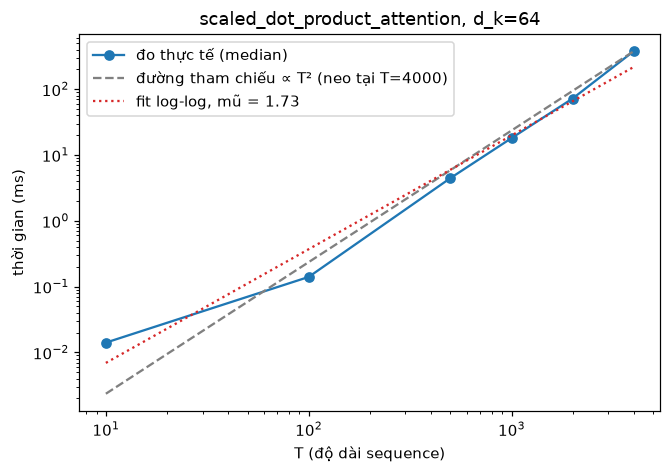

In [33]:
fig, ax = plt.subplots(figsize=(6.2, 4.4))
ax.loglog(tim['T'], tim['median time (ms)'], 'o-', label='đo thực tế (median)')
ref = tim['median time (ms)'].iloc[-1] * (tim['T'] / tim['T'].iloc[-1]) ** 2
ax.loglog(tim['T'], ref, '--', c='gray', label='đường tham chiếu ∝ T² (neo tại T=4000)')
ax.loglog(tim['T'], np.exp(icpt) * tim['T'] ** slope_all, ':', c='C3', label=f'fit log-log, mũ = {slope_all:.2f}')
ax.set_xlabel('T (độ dài sequence)'); ax.set_ylabel('thời gian (ms)'); ax.legend(); ax.set_title('scaled_dot_product_attention, d_k=64')
plt.tight_layout(); plt.savefig(OUT / 'seq_length_cost.png', bbox_inches='tight'); plt.show()

In [34]:
print('Quan sát từ số liệu:')
print('- Số phần tử: ' + ', '.join(f'T={t}: {t*t:,}' for t in Ts) + '. Gấp đôi T thì số phần tử gấp đúng 4 lần (vd. 500 -> 1000: 250,000 -> 1,000,000).')
print(f'- Bộ nhớ float32 chỉ cho ma trận A: T=1000: {1000**2*4/1e6:.0f} MB; T=10000: {10000**2*4/1e6:.0f} MB (cho MỘT ma trận, một câu, một head; training còn lưu cả scores và gradient).')
print('- Thời gian đo (median): ' + ', '.join(f'T={int(r['T'])}: {r["median time (ms)"]:.3f} ms' for _, r in tim.iterrows()))
print(f'- Hệ số mũ hồi quy log-log: {slope_all:.2f} (tất cả điểm), {slope_big:.2f} (T>=500). Hệ số cục bộ giữa các T liên tiếp: ' + ', '.join(f'{v:.2f}' for v in local) + '.')
print(f'- Với T nhỏ (10, 100) thời gian bị chi phối bởi overhead gọi hàm/Python/kiểm tra shape nên đường cong phẳng hơn T² (hệ số cục bộ đầu = {local[0]:.2f}); khi T lớn hệ số tiến gần tới {slope_big:.2f}. '
      f'Các phép nhân ma trận chi phí T²·d_k, softmax chi phí T², nên lý thuyết là O(T²) ở d_k cố định.')
print(f'- Thời gian T=4000 / T=2000 = {tim["median time (ms)"].iloc[-1] / tim["median time (ms)"].iloc[-2]:.2f}x (lý thuyết 4x nếu thuần T²; số đo còn bị ảnh hưởng bởi cache và đa luồng BLAS).')

Quan sát từ số liệu:
- Số phần tử: T=10: 100, T=100: 10,000, T=500: 250,000, T=1000: 1,000,000, T=10000: 100,000,000. Gấp đôi T thì số phần tử gấp đúng 4 lần (vd. 500 -> 1000: 250,000 -> 1,000,000).
- Bộ nhớ float32 chỉ cho ma trận A: T=1000: 4 MB; T=10000: 400 MB (cho MỘT ma trận, một câu, một head; training còn lưu cả scores và gradient).
- Thời gian đo (median): T=10: 0.014 ms, T=100: 0.140 ms, T=500: 4.465 ms, T=1000: 18.066 ms, T=2000: 72.173 ms, T=4000: 377.252 ms
- Hệ số mũ hồi quy log-log: 1.73 (tất cả điểm), 2.12 (T>=500). Hệ số cục bộ giữa các T liên tiếp: 1.00, 2.15, 2.02, 2.00, 2.39.
- Với T nhỏ (10, 100) thời gian bị chi phối bởi overhead gọi hàm/Python/kiểm tra shape nên đường cong phẳng hơn T² (hệ số cục bộ đầu = 1.00); khi T lớn hệ số tiến gần tới 2.12. Các phép nhân ma trận chi phí T²·d_k, softmax chi phí T², nên lý thuyết là O(T²) ở d_k cố định.
- Thời gian T=4000 / T=2000 = 5.23x (lý thuyết 4x nếu thuần T²; số đo còn bị ảnh hưởng bởi cache và đa luồng BLAS).


**Diễn giải của sinh viên**

Ma trận attention T × T nên số phần tử tăng theo T²: gấp đôi T thì gấp 4 lần (T = 1000: 10⁶ phần tử, 4 MB float32; T = 10 000: 10⁸ phần tử, 400 MB cho một ma trận của một câu, một head). Thời gian đo tăng từ dưới 0.1 ms (T = 10) lên vài trăm ms (T = 4000); hệ số mũ log-log xấp xỉ 2 khi T ≥ 500, còn thấp hơn nếu tính cả T nhỏ vì overhead gọi hàm chiếm phần lớn. Với sequence rất dài, cả thời gian và bộ nhớ tăng theo T², trong khi RNN có chi phí gần tuyến tính theo T (nhưng tuần tự). Vì vậy attention giải quyết một số vấn đề của RNN nhưng không phải lúc nào cũng thay thế được RNN.

## B10. Application — Context-aware sentiment (mục 26)

Pipeline: `raw text → tokenizer (LAB 05) → embedding (+position) → self-attention → context vectors → mean pool → classifier → sentiment`. Dùng model **Self-attention seed 42 đã train ở B8** (LSTM seed 42 để đối chiếu).

Ba câu của đề (nhãn kỳ vọng: positive, negative, positive). Mình **thêm 4 câu khó** (đánh dấu `extra`) để tìm ca sai: phủ định kép, "not bad", mỉa mai, "not good".

Attention của classifier là ma trận `T × T` trên token; hình bên phải vẽ *attention nhận được* của mỗi token (trung bình theo cột = trung bình trên mọi query), chỉ là một cách tóm tắt.

In [35]:
app = [('I like this movie.', 1, 'given'),
       ('I do not like this movie.', 0, 'given'),
       ('I thought this movie would be bad, but it was actually excellent.', 1, 'given'),
       ("I can't say I didn't enjoy this movie.", 1, 'extra: double negation'),
       ('This movie is not bad at all.', 1, 'extra: negated negative'),
       ('Oh great, another two hours of my life wasted.', 0, 'extra: sarcasm'),
       ('This film was not good.', 0, 'extra: negation')]
LBL = {0: 'negative', 1: 'positive'}
am.set_seed(SEED)
rows, expl = [], []
for text, y_true, tag in app:
    e = am.explain(models42['Self-attention'], text, vocab, dev)
    p_lstm = float(am.prob_positive(models42['LSTM'], [am.lab05.tokenize_text(text)], vocab, dev)[0])
    pred = int(e['p_pos'] >= 0.5)
    top3_idx = np.argsort(-e['received'])[:3]
    rows.append({'sentence': text, 'tag': tag, 'expected': LBL[y_true], 'attention pred': LBL[pred], 'p(positive)': e['p_pos'],
                 'confidence': max(e['p_pos'], 1 - e['p_pos']), 'correct': pred == y_true,
                 'top-3 received': ', '.join(f"{e['tokens'][i]} ({e['received'][i]:.2f})" for i in top3_idx),
                 'LSTM p(positive)': p_lstm, 'LSTM correct': int(p_lstm >= 0.5) == y_true})
    expl.append(e)
app_df = pd.DataFrame(rows)
app_df.drop(columns=['top-3 received']).round(4)

,sentence,tag,expected,attention pred,p(positive),confidence,correct,LSTM p(positive),LSTM correct
0,I like this movie.,given,positive,negative,0.0099,0.9901,False,0.5495,True
1,I do not like this movie.,given,negative,negative,0.0343,0.9657,True,0.5323,False
2,"I thought this movie would be bad, but it was ...",given,positive,negative,0.0032,0.9968,False,0.2872,False
3,I can't say I didn't enjoy this movie.,extra: double negation,positive,negative,0.2222,0.7778,False,0.6670,True
4,This movie is not bad at all.,extra: negated negative,positive,negative,0.0002,0.9998,False,0.1055,False
5,"Oh great, another two hours of my life wasted.",extra: sarcasm,negative,positive,0.9537,0.9537,False,0.8130,False
6,This film was not good.,extra: negation,negative,negative,0.3336,0.6664,True,0.3909,True


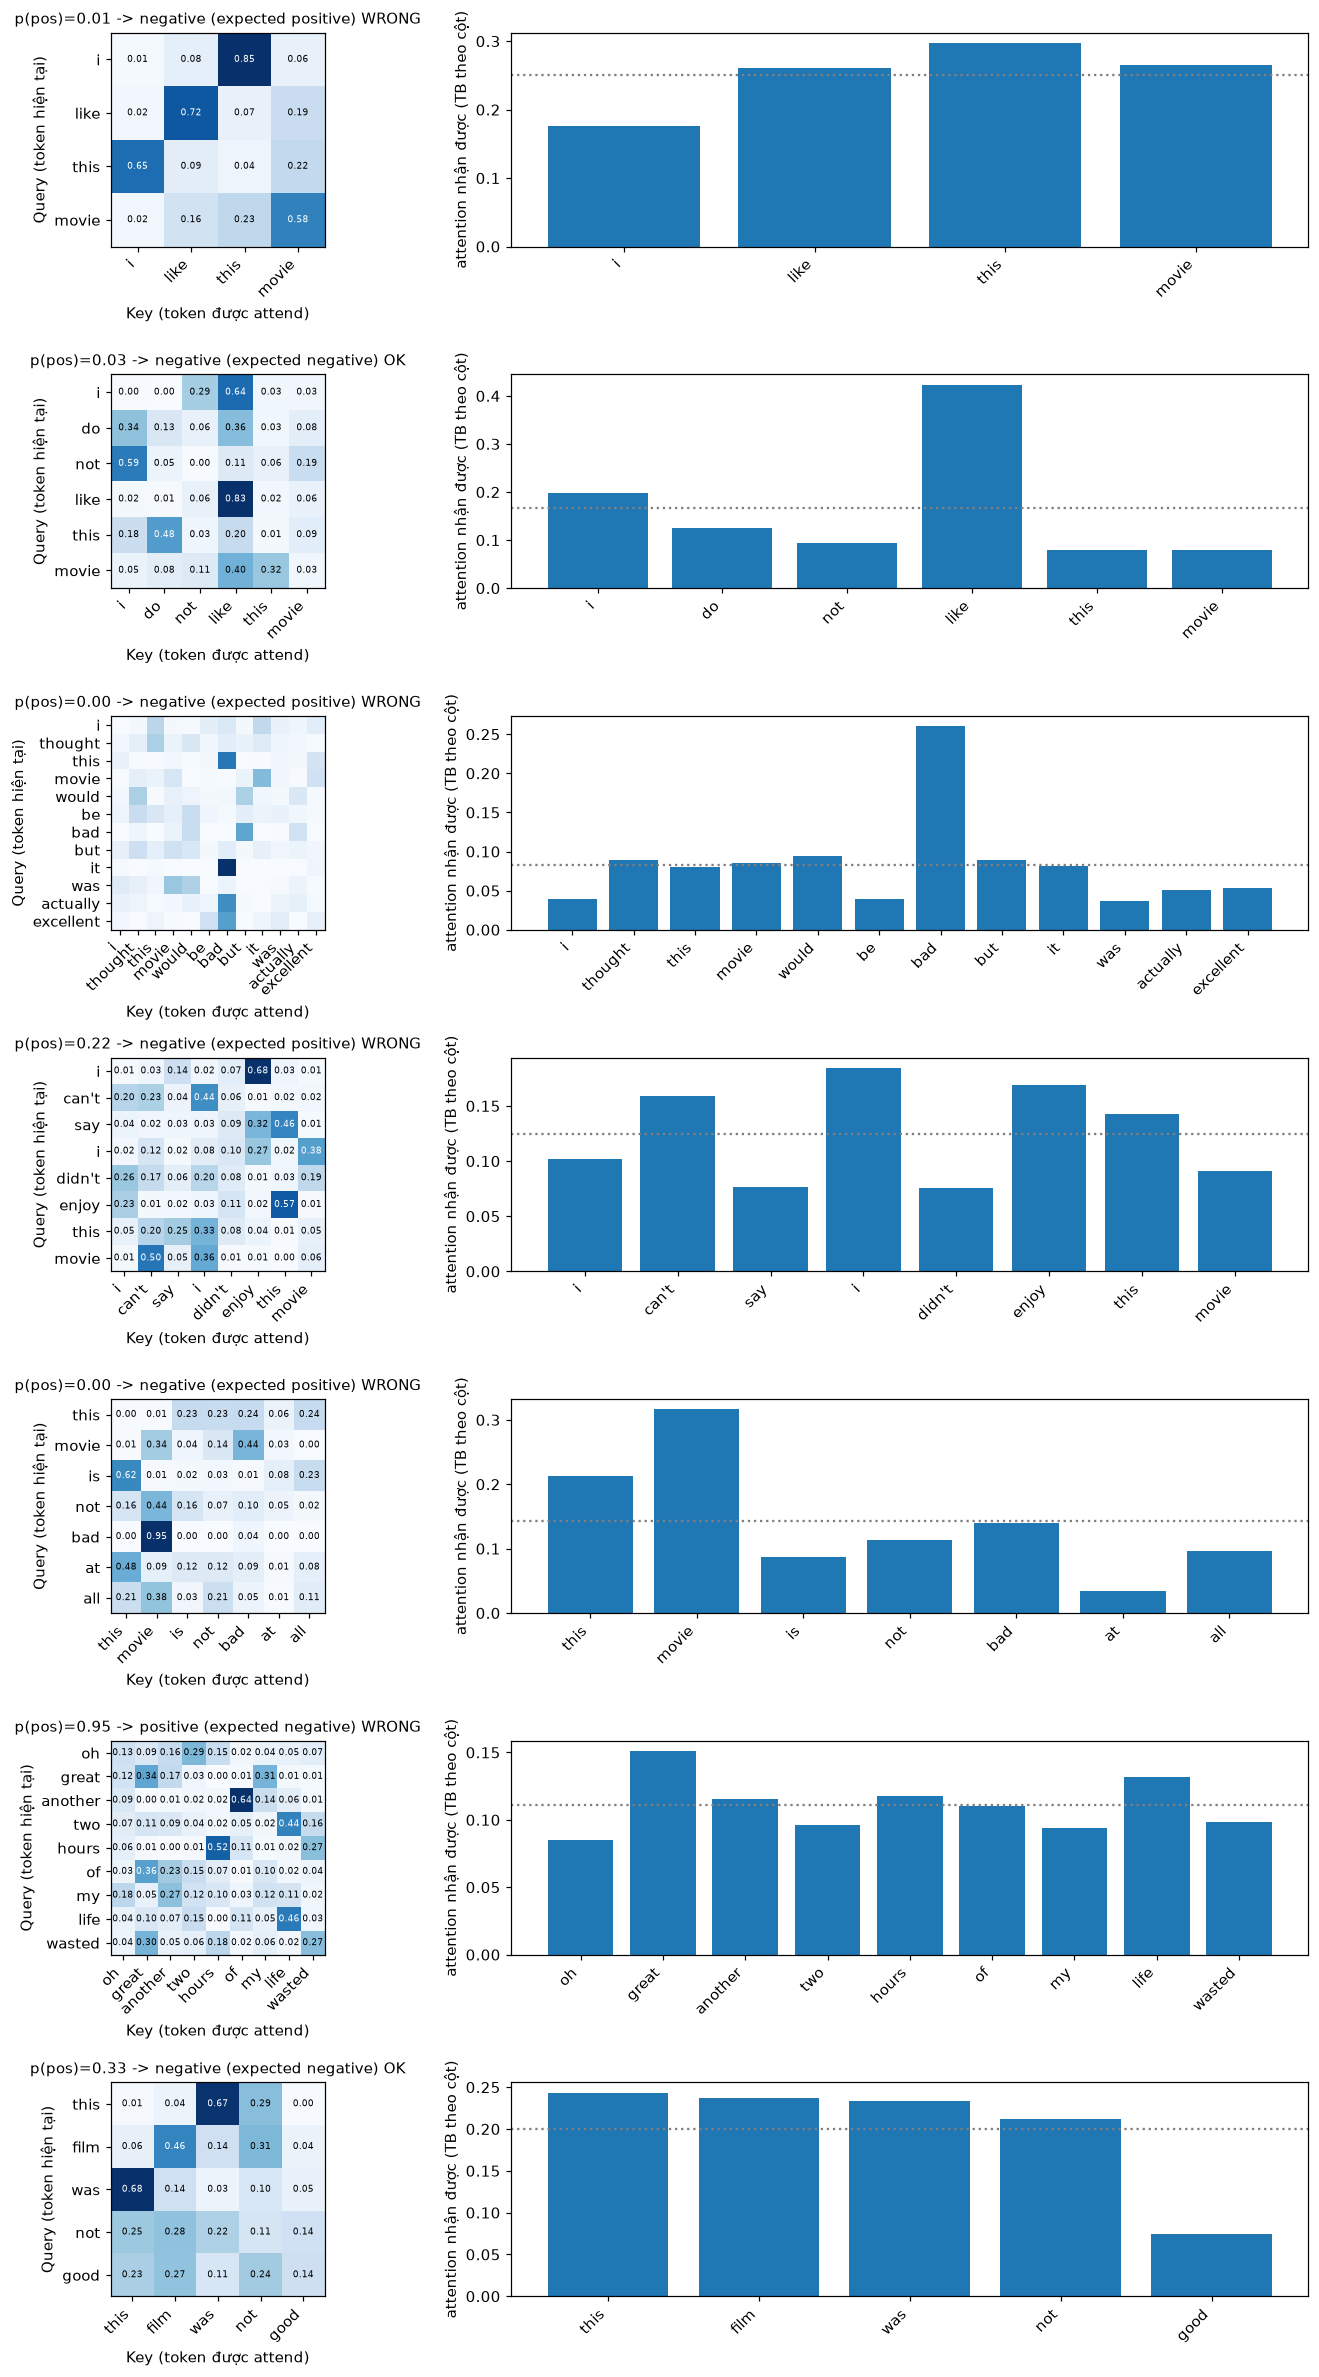

In [36]:
n = len(app)
fig, axes = plt.subplots(n, 2, figsize=(13, 3.1 * n), gridspec_kw={'width_ratios': [1.0, 1.3]})
for i, (e, r) in enumerate(zip(expl, rows)):
    toks = e['tokens']
    heatmap(axes[i, 0], e['A'], toks, toks, f"p(pos)={r['p(positive)']:.2f} -> {r['attention pred']} (expected {r['expected']}) {'OK' if r['correct'] else 'WRONG'}", fmt='{:.2f}', fs=6)
    axes[i, 1].bar(range(len(toks)), e['received'], color='C0'); axes[i, 1].set_xticks(range(len(toks))); axes[i, 1].set_xticklabels(toks, rotation=45, ha='right')
    axes[i, 1].axhline(1 / len(toks), ls=':', c='gray'); axes[i, 1].set_ylabel('attention nhận được (TB theo cột)')
plt.tight_layout(); plt.savefig(OUT / 'application_attention.png', bbox_inches='tight'); plt.show()

In [37]:
n_ok = int(app_df.correct.sum())
print('Quan sát từ số liệu:')
for r in rows:
    print(f"- [{r['tag']}] \"{r['sentence']}\" -> {r['attention pred']} (p_pos={r['p(positive)']:.3f}), kỳ vọng {r['expected']}: {'ĐÚNG' if r['correct'] else 'SAI'}; top-3 attention nhận được: {r['top-3 received']}; LSTM p_pos={r['LSTM p(positive)']:.3f} ({'đúng' if r['LSTM correct'] else 'sai'}).")
given_ok = int(app_df.iloc[:3].correct.sum())
print(f'- Ba câu của đề: {given_ok}/3 đúng. Tất cả {len(app)} câu: {n_ok}/{len(app)} đúng. Có ít nhất 1 đúng: {bool(n_ok >= 1)}; có ít nhất 1 sai: {bool(n_ok < len(app))}.')
print('- Với 7 câu rất ít, đây chỉ là ví dụ minh họa, không phải đánh giá thống kê. Top-3 attention không tự cho biết token đó "làm" model dự đoán thế nào (xem phần kiểm tra bằng xóa token ở error analysis).')

Quan sát từ số liệu:
- [given] "I like this movie." -> negative (p_pos=0.010), kỳ vọng positive: SAI; top-3 attention nhận được: this (0.30), movie (0.27), like (0.26); LSTM p_pos=0.549 (đúng).
- [given] "I do not like this movie." -> negative (p_pos=0.034), kỳ vọng negative: ĐÚNG; top-3 attention nhận được: like (0.42), i (0.20), do (0.12); LSTM p_pos=0.532 (sai).
- [given] "I thought this movie would be bad, but it was actually excellent." -> negative (p_pos=0.003), kỳ vọng positive: SAI; top-3 attention nhận được: bad (0.26), would (0.09), thought (0.09); LSTM p_pos=0.287 (sai).
- [extra: double negation] "I can't say I didn't enjoy this movie." -> negative (p_pos=0.222), kỳ vọng positive: SAI; top-3 attention nhận được: i (0.18), enjoy (0.17), can't (0.16); LSTM p_pos=0.667 (đúng).
- [extra: negated negative] "This movie is not bad at all." -> negative (p_pos=0.000), kỳ vọng positive: SAI; top-3 attention nhận được: movie (0.32), this (0.21), bad (0.14); LSTM p_pos=0.106 (sai).
- [

**Diễn giải của sinh viên**

Đúng: "I do not like this movie." (p_pos = 0.034). Attention nhận được cao nhất ở `like` (0.42), `i`, `do`; `not` chỉ khoảng 0.09, nên dự đoán đúng không cho thấy attention đã xử lý phủ định. Sai: "I like this movie." (p_pos = 0.010, kỳ vọng positive) và "I thought this movie would be bad, but it was actually excellent." (p_pos = 0.003, kỳ vọng positive); ở câu sau `bad` nhận 0.26 attention còn `excellent` chỉ khoảng 0.05. Giả thuyết của mình: model được train trên review dài, dựa nhiều vào cue từ vựng và mean pooling nên "but … excellent" không đủ lật dự đoán. Đây mới chỉ là giả thuyết; muốn kiểm tra phải xóa/đổi token như ở phần error analysis. Với 7 câu, kết quả chỉ mang tính minh họa.

## C. Error analysis (mục 27) — dữ liệu và kiểm tra bằng perturbation

Model phân tích: **Self-attention seed 42** (B8). 6 ca được chọn **thủ công** từ tập test (3 đúng, 3 sai) sau khi xem một danh sách ứng viên; không chọn ngẫu nhiên nên không đại diện cho toàn bộ lỗi. Nhãn lỗi (`negation`, `truncation`, …) và "token mà người đọc cho là quan trọng" trong code là **giả thuyết** của mình, được kiểm tra bằng perturbation bên dưới.

Với mỗi ca, để kiểm chứng giả thuyết (thay vì kết luận "attention nhìn sai nên model sai") ta đo `p(positive)` khi:

* xóa token nhận nhiều attention nhất (top-1) / top-3 (theo attention *nhận được*, trung bình theo cột);
* xóa nhóm token mà người đọc cho là quan trọng (giả thuyết);
* **đối chứng**: xóa 3 token ngẫu nhiên (100 lần, lấy trung bình ± std);
* với review dài hơn 100 token: chỉ đưa 100 token **cuối** thay vì 100 token đầu (kiểm tra giả thuyết truncation).

In [38]:
test_df = data.test.set_index('sample_id')
CASES = [  # (sample_id, kind, nhãn lỗi, các nhóm token 'người đọc cho là quan trọng' (giả thuyết))
    ('provided_csv:20897', 'wrong',   'negation / ambiguous wording', {'phủ định "not worth"': ['not', 'worth'], 'khen "pleasantly surprised"': ['pleasantly', 'surprised']}),
    ('provided_csv:112',   'wrong',   'sarcasm',                      {'"terrific" (mỉa)': ['terrific'], 'chê "boring", "pity"': ['boring', 'pity']}),
    ('provided_csv:25358', 'wrong',   'truncation / long-range dependency', {'từ khen mở đầu "great", "popular"': ['great', 'popular']}),
    ('provided_csv:35024', 'correct', '(không lỗi) cue sentiment rõ',  {'"cheap", "painful"': ['cheap', 'painful'], '"avoid"': ['avoid']}),
    ('provided_csv:6028',  'correct', '(không lỗi) cue sentiment rõ',  {'"great", "fantastic", "superb"': ['great', 'fantastic', 'superb']}),
    ('provided_csv:3286',  'correct', '(không lỗi) negation nhẹ',       {'"entertained"': ['entertained'], '"not much more"': ['not', 'much', 'more']}),
]
rng_c = np.random.default_rng(SEED)
M = models42['Self-attention']
LBLN = {0: 'neg', 1: 'pos'}
def pp(toks): return float(am.prob_positive(M, [toks], vocab, dev)[0])
def lo(p): p = min(max(p, 1e-9), 1 - 1e-9); return float(np.log(p / (1 - p)))   # log-odds (p bão hòa gần 0/1 nên p khó thấy thay đổi)
def drop(toks, bad): return [t for t in toks if t not in set(bad)]
evidence, rows_c = [], []
for sid, kind, cat, groups in CASES:
    r = test_df.loc[sid]
    all_tokens = am.lab05.tokenize_text(r.text)
    e = am.explain(M, r.text, vocab, dev)
    toks = e['tokens']                                  # sau truncation (100 token đầu)
    p0 = e['p_pos']; pred = int(p0 >= 0.5)
    assert (pred == r.label) == (kind == 'correct'), (sid, pred, r.label)
    order_ = np.argsort(-e['received'])
    top1, top3_ = [toks[order_[0]]], [toks[i] for i in order_[:3]]
    p_top1, p_top3 = pp(drop(toks, top1)), pp(drop(toks, top3_))
    ctrl = []
    for _ in range(100):
        kill = set(rng_c.choice(len(toks), size=3, replace=False).tolist())
        ctrl.append(pp([t for i, t in enumerate(toks) if i not in kill]) - p0)
    grp = {name: pp(drop(toks, g)) for name, g in groups.items()}
    p_tail = pp(all_tokens[-am.MAX_LEN:]) if len(all_tokens) > am.MAX_LEN else None
    ev = {'sample_id': sid, 'kind': kind, 'label': LBLN[int(r.label)], 'pred': LBLN[pred], 'p_pos': p0,
          'n_tokens_total': len(all_tokens), 'n_tokens_seen': len(toks), 'category': cat,
          'top3_received': [(toks[i], float(e['received'][i])) for i in order_[:3]],
          'delete_top1': {'token': top1[0], 'p_pos': p_top1}, 'delete_top3': {'tokens': top3_, 'p_pos': p_top3},
          'delete_groups': {k: v for k, v in grp.items()}, 'control_delta_mean': float(np.mean(ctrl)), 'control_delta_std': float(np.std(ctrl)),
          'last100_p_pos': p_tail, 'logodds': {'base': lo(p0), 'delete_top1': lo(p_top1), 'delete_top3': lo(p_top3), 'groups': {k: lo(v) for k, v in grp.items()}, 'last100': None if p_tail is None else lo(p_tail)}, 'visible_text': ' '.join(toks)}
    evidence.append(ev)
    rows_c.append({'sample_id': sid, 'true': ev['label'], 'pred': ev['pred'], 'p(pos)': p0, 'len': f"{len(toks)}/{len(all_tokens)}",
                   'top-3 attended': ', '.join(f'{t} ({w:.2f})' for t, w in ev['top3_received']),
                   'p after del top-1': p_top1, 'p after del top-3': p_top3, 'ctrl Δp (3 random)': f"{np.mean(ctrl):+.3f}±{np.std(ctrl):.3f}",
                   'p last-100': p_tail})
pd.DataFrame(rows_c).round(4)

,sample_id,true,pred,p(pos),len,top-3 attended,p after del top-1,p after del top-3,ctrl Δp (3 random),p last-100
0,provided_csv:20897,neg,pos,0.9996,42/42,"pleasantly (0.08), cameos (0.05), the (0.05)",0.9969,0.9864,-0.002±0.003,NaN
1,provided_csv:112,neg,pos,0.9891,41/41,"terrific (0.10), fun (0.08), better (0.06)",0.7057,0.5835,-0.083±0.100,NaN
2,provided_csv:25358,neg,pos,0.9909,100/742,"great (0.03), numerous (0.03), in (0.03)",0.9824,0.9877,-0.000±0.004,0.4066
3,provided_csv:35024,neg,neg,0.0085,51/51,"cheap (0.10), painful (0.05), very (0.04)",0.0396,0.0646,+0.002±0.012,NaN
4,provided_csv:6028,pos,pos,0.9996,42/42,"composition (0.09), our (0.05), great (0.05)",0.9993,0.9973,-0.000±0.001,NaN
5,provided_csv:3286,pos,pos,0.7203,51/51,"much (0.05), all (0.05), entertained (0.04)",0.7629,0.8789,+0.104±0.051,NaN


In [39]:
import textwrap
for ev in evidence:
    print('=' * 100)
    print(f"{ev['sample_id']} | {ev['kind'].upper()} | true={ev['label']} pred={ev['pred']} p(pos)={ev['p_pos']:.4f} | tokens seen {ev['n_tokens_seen']}/{ev['n_tokens_total']} | nhóm lỗi: {ev['category']}")
    print(textwrap.fill(ev['visible_text'], 150))
    print('top-3 attention nhận được:', ev['top3_received'])
    print(f"xóa top-1 '{ev['delete_top1']['token']}': p(pos) {ev['p_pos']:.4f} -> {ev['delete_top1']['p_pos']:.4f}")
    print(f"xóa top-3 {ev['delete_top3']['tokens']}: -> {ev['delete_top3']['p_pos']:.4f}")
    for k, v in ev['delete_groups'].items(): print(f"xóa nhóm {k}: -> {v:.4f}")
    print(f"đối chứng (xóa 3 token ngẫu nhiên): Δp = {ev['control_delta_mean']:+.4f} ± {ev['control_delta_std']:.4f}")
    if ev['last100_p_pos'] is not None: print(f"chỉ đưa 100 token CUỐI: p(pos) = {ev['last100_p_pos']:.4f}")

provided_csv:20897 | WRONG | true=neg pred=pos p(pos)=0.9996 | tokens seen 42/42 | nhóm lỗi: negation / ambiguous wording
definitely not worth the rental but if you catch it on cable you'll be pleasantly surprised by the cameos iman's appearance is especially self
deprecating it's also an opportunity to watch all the male supporting cast members from the sopranos typecast themselves
top-3 attention nhận được: [('pleasantly', 0.0752396360039711), ('cameos', 0.04853949695825577), ('the', 0.04560472071170807)]
xóa top-1 'pleasantly': p(pos) 0.9996 -> 0.9969
xóa top-3 ['pleasantly', 'cameos', 'the']: -> 0.9864
xóa nhóm phủ định "not worth": -> 0.9974
xóa nhóm khen "pleasantly surprised": -> 0.9922
đối chứng (xóa 3 token ngẫu nhiên): Δp = -0.0023 ± 0.0026
provided_csv:112 | WRONG | true=neg pred=pos p(pos)=0.9891 | tokens seen 41/41 | nhóm lỗi: sarcasm
it's terrific when a funny movie doesn't make smile you what a pity this film is very boring and so long it's simply painfull the story is s

In [40]:
# Thống kê mô tả trên toàn test set (không nhân quả): lỗi theo độ dài và theo có/không có token phủ định
y_all, p_all = y_test, probs42['Self-attention']
pred_all = (p_all >= 0.5).astype(int)
lens = np.array([len(am.lab05.tokenize_text(t)) for t in data.test.text])
NEG = {'not', 'no', 'never', "don't", "doesn't", "didn't", "isn't", "wasn't", "can't", "couldn't", "won't", "wouldn't", "aren't", "weren't", "nothing", "nobody"}
has_neg = np.array([any(t in NEG for t in am.lab05.tokenize_text(t)[:am.MAX_LEN]) for t in data.test.text])
def acc(mask): return float((pred_all[mask] == y_all[mask]).mean()), int(mask.sum())
grp_rows = []
for name, mask in [('<= 100 token (không bị cắt)', lens <= 100), ('> 100 token (bị cắt)', lens > 100),
                   ('> 300 token', lens > 300), ('có token phủ định trong 100 token đầu', has_neg), ('không có token phủ định', ~has_neg)]:
    a_, n_ = acc(mask); grp_rows.append({'nhóm test': name, 'n': n_, 'accuracy': a_})
grp_df = pd.DataFrame(grp_rows)
lstm_pred = (probs42['LSTM'] >= 0.5).astype(int)
grp_df['LSTM accuracy (cùng nhóm)'] = [float((lstm_pred[m] == y_all[m]).mean()) for m in [lens <= 100, lens > 100, lens > 300, has_neg, ~has_neg]]
grp_df

,nhóm test,n,accuracy,LSTM accuracy (cùng nhóm)
0,<= 100 token (không bị cắt),1141,0.879053,0.834356
1,> 100 token (bị cắt),8859,0.797268,0.748504
2,> 300 token,2340,0.738462,0.688034
3,có token phủ định trong 100 token đầu,7158,0.809444,0.755658
4,không có token phủ định,2842,0.799437,0.764954


In [41]:
json.dump({'model': 'Self-attention seed 42', 'cases': evidence,
           'group_accuracy': grp_df.round(4).to_dict('records')}, open(OUT / 'error_analysis_evidence.json', 'w', encoding='utf-8'), ensure_ascii=False, indent=1)
print('Quan sát từ số liệu:')
for ev in evidence:
    L = ev['logodds']
    g = ', '.join(f"{k}: p {ev['p_pos']:.3f}->{v:.3f} (log-odds {L['base']:+.2f}->{L['groups'][k]:+.2f})" for k, v in ev['delete_groups'].items())
    tail = f"; 100 token cuối: p={ev['last100_p_pos']:.3f} (log-odds {L['last100']:+.2f})" if ev['last100_p_pos'] is not None else ''
    print(f"- {ev['sample_id']} ({ev['kind']}, true={ev['label']}, pred={ev['pred']}, p={ev['p_pos']:.3f}, log-odds {L['base']:+.2f}): top-3={[t for t,_ in ev['top3_received']]}; "
          f"xóa top-1 -> p {ev['delete_top1']['p_pos']:.3f} (log-odds {L['delete_top1']:+.2f}), xóa top-3 -> p {ev['delete_top3']['p_pos']:.3f} (log-odds {L['delete_top3']:+.2f}); "
          f"xóa nhóm giả thuyết [{g}]; đối chứng Δp={ev['control_delta_mean']:+.3f}{tail}.")
print('- Accuracy theo nhóm:'); print(grp_df.round(4).to_string(index=False))
print('- Lưu ý: n=6 ca chọn tay và perturbation bằng cách xóa token (làm lệch phân phối đầu vào) -> chỉ là bằng chứng gợi ý cho giả thuyết, không chứng minh nguyên nhân.')

Quan sát từ số liệu:
- provided_csv:20897 (wrong, true=neg, pred=pos, p=1.000, log-odds +7.84): top-3=['pleasantly', 'cameos', 'the']; xóa top-1 -> p 0.997 (log-odds +5.77), xóa top-3 -> p 0.986 (log-odds +4.28); xóa nhóm giả thuyết [phủ định "not worth": p 1.000->0.997 (log-odds +7.84->+5.94), khen "pleasantly surprised": p 1.000->0.992 (log-odds +7.84->+4.85)]; đối chứng Δp=-0.002.
- provided_csv:112 (wrong, true=neg, pred=pos, p=0.989, log-odds +4.51): top-3=['terrific', 'fun', 'better']; xóa top-1 -> p 0.706 (log-odds +0.87), xóa top-3 -> p 0.584 (log-odds +0.34); xóa nhóm giả thuyết ["terrific" (mỉa): p 0.989->0.706 (log-odds +4.51->+0.87), chê "boring", "pity": p 0.989->0.971 (log-odds +4.51->+3.53)]; đối chứng Δp=-0.083.
- provided_csv:25358 (wrong, true=neg, pred=pos, p=0.991, log-odds +4.69): top-3=['great', 'numerous', 'in']; xóa top-1 -> p 0.982 (log-odds +4.02), xóa top-3 -> p 0.988 (log-odds +4.39); xóa nhóm giả thuyết [từ khen mở đầu "great", "popular": p 0.991->0.985 (lo